# Diagnóstico de marca empleadora — Deloitte vs. Big Four (PwC, EY, KPMG)
## Análisis de sentimiento (DistilBERT) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH.** El departamento de Recursos Humanos de Deloitte pide a Data Science un diagnóstico de la firma como empleador a partir de las reseñas públicas de Glassdoor: qué puntos fuertes puede explotar en *employer branding* y selección, y qué áreas de mejora están dañando la reputación o provocando salidas. Todo ello **comparado con sus competidores directos**, porque un problema solo es prioritario si estamos peor que el mercado.

**Empresa y peers.** Empresa objetivo: **Deloitte**. Peers: **PwC, EY y KPMG**. Las cuatro forman el grupo *Big Four* de servicios profesionales (auditoría, fiscal, consultoría, *advisory*): ofrecen los mismos servicios, reclutan en las mismas universidades y programas de graduados, y compiten por el mismo perfil de talento (auditores, consultores, analistas, tecnología). Todas superan ampliamente las 300 reseñas (entre 25.000 y 40.000 en la ventana 2018-2023), por lo que la comparación es estadísticamente sólida.

**No hay variable objetivo:** es un ejercicio de NLP descriptivo (sentimiento y *topics*), no de predicción.

| Sección | Contenido |
|---|---|
| 0 | Configuración, carga y preparación de datos |
| 1 | EDA: volumen, rating, recomendación, actuales vs. antiguos, evolución temporal |
| 2 | Sentimiento en pros y cons con un transformer preentrenado (control de calidad) |
| 3 | Topic modeling con BERTopic (un modelo para pros y otro para cons, común a las 4 firmas) y agrupación en categorías de negocio |
| 4 | Comparación con peers: peso de cada categoría, balance neto, gap y contraste con rating/recomendación |
| 5 | Empleados actuales vs. antiguos (motivos de salida) |
| 6 | Matriz de priorización, recomendaciones para RRHH y limitaciones |
| 7 | Extra: evolución temporal de las categorías y análisis por recomendación / antigüedad |
| 8 | Conclusiones |

> **Reproducibilidad.** Semilla fija (`SEED = 42`) en el muestreo, en UMAP y en la selección de ejemplos. El notebook se ejecuta de arriba abajo sin errores en CPU (≈15-20 min en un portátil; menos con GPU en Google Colab).

In [1]:
# En Google Colab: transformers y torch ya vienen instalados; BERTopic no. Descomenta la siguiente línea.
# !pip install -q "bertopic<0.18" "sentence-transformers<4" umap-learn hdbscan pyarrow
# En local: pip install -r requirements.txt   (ver README.md)

---
## 0. Configuración, carga y preparación

**Asunciones y decisiones de preparación**

- Trabajo con una **muestra aleatoria de 2.000 reseñas por empresa** (semilla 42), como sugiere el enunciado, para que el transformer de sentimiento y BERTopic corran en tiempos razonables. Con el mismo tamaño por empresa, además, ninguna firma domina el modelo de topics conjunto. El EDA descriptivo (sección 1), que no necesita modelos, se calcula sobre **todas** las reseñas disponibles de las cuatro firmas.
- `current` se separa en **situación** (Actual / Antiguo) y **antigüedad** (tramos de Glassdoor: "less than 1 year", "more than 1 year", ... que interpreto como < 1 año, 1-3, 3-5, 5-8, 8-10, > 10 años; si no consta, `n/d`).
- `recommend`: `v` = Sí, `o` = Sin opinión, `x` = No. El **% que recomienda** se calcula sobre el total de reseñas (incluyendo las que no opinan), que es la lectura más conservadora.
- Los textos se limpian solo de saltos de línea y espacios repetidos: los modelos transformer trabajan mejor con el texto original (mayúsculas, puntuación) que con texto "lematizado".
- No hay nulos en el fichero del profesor (se comprueba en código).

In [2]:
import os, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 160)

# ---------------- Parámetros del análisis ----------------
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

TARGET = 'Deloitte'                       # empresa a diagnosticar
PEERS = ['PwC', 'EY', 'KPMG']              # competidores (mismo sector y tamaño comparable)
FIRMS = [TARGET] + PEERS
MAX_POR_EMPRESA = 2000                    # tope de reseñas por empresa (muestra con semilla fija)
RUTA_PARQUET = 'glassdoor_reviews_hr.parquet'

# Caché opcional de resultados costosos (sentimiento, embeddings). Si no existe, se recalcula todo.
USAR_CACHE = True
CACHE_DIR = Path('cache'); CACHE_DIR.mkdir(exist_ok=True)
FIG_DIR = Path('figuras'); FIG_DIR.mkdir(exist_ok=True)   # las figuras se guardan en PNG para la presentación

# Dispositivo: GPU (CUDA) en Colab, MPS en Mac Apple Silicon, CPU en el resto
if torch.cuda.is_available():
    DEVICE = 'cuda'
elif getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'
print(f'Dispositivo de cómputo: {DEVICE} | torch {torch.__version__}')

# ---------------- Estilo de gráficos ----------------
sns.set_theme(style='whitegrid', font_scale=0.95)
COLOR_TARGET = '#1B7F3B'                                   # la empresa objetivo siempre en verde
COLOR_PEERS = ['#8C8C8C', '#B9B9B9', '#5A5A5A', '#D5D5D5', '#3A3A3A']
COLORES = {TARGET: COLOR_TARGET, **{p: COLOR_PEERS[i] for i, p in enumerate(PEERS)}}
COLOR_MEDIA_PEERS = '#8C8C8C'

def guardar(fig, nombre):
    """Guarda la figura en figuras/<nombre>.png (para la presentación) y la muestra."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{nombre}.png', dpi=150, bbox_inches='tight')
    plt.show()

Dispositivo de cómputo: mps | torch 2.2.2


In [3]:
# Carga solo las empresas necesarias, sin leer el fichero entero (filtro a nivel de Parquet)
t0 = time.time()
raw = pd.read_parquet(RUTA_PARQUET, filters=[('firm', 'in', FIRMS)])
print(f'Cargadas {len(raw):,} reseñas de {raw.firm.nunique()} empresas en {time.time()-t0:.1f} s')
print('\nReseñas disponibles por empresa:')
print(raw['firm'].value_counts().to_string())
print('\nNulos por columna:', raw.isna().sum().to_dict())
print('Ventana temporal:', raw.date_review.min(), '→', raw.date_review.max())

Cargadas 129,115 reseñas de 4 empresas en 0.4 s

Reseñas disponibles por empresa:
firm
Deloitte    40199
PwC         33558
EY          29601
KPMG        25757

Nulos por columna: {'firm': 0, 'date_review': 0, 'current': 0, 'overall_rating': 0, 'recommend': 0, 'pros': 0, 'cons': 0}
Ventana temporal: 2018-07-27 → 2023-04-11


In [4]:
# ---------------- Preparación de variables ----------------
ORDEN_ANTIG = ['< 1 año', '1-3 años', '3-5 años', '5-8 años', '8-10 años', '> 10 años', 'n/d']
MAPA_ANTIG = {'less than 1': '< 1 año', 'more than 1': '1-3 años', 'more than 3': '3-5 años',
              'more than 5': '5-8 años', 'more than 8': '8-10 años', 'more than 10': '> 10 años'}

def situacion(s):
    s = str(s).lower()
    if s.startswith('current'):
        return 'Actual'
    if s.startswith('former'):
        return 'Antiguo'
    return 'Desconocido'

def antiguedad(s):
    m = re.search(r'(less than|more than) (\d+) year', str(s))
    return MAPA_ANTIG.get(f'{m.group(1)} {m.group(2)}', 'n/d') if m else 'n/d'

def preparar(d):
    d = d.copy()
    d['situacion'] = d['current'].map(situacion)
    d['antiguedad'] = pd.Categorical(d['current'].map(antiguedad), categories=ORDEN_ANTIG, ordered=True)
    d['recomienda'] = d['recommend'].map({'v': 'Sí', 'o': 'Sin opinión', 'x': 'No'})
    d['date_review'] = pd.to_datetime(d['date_review'])
    d['anio'] = d['date_review'].dt.year
    d['periodo'] = pd.cut(d['anio'], bins=[2017, 2019, 2021, 2023], labels=['2018-19', '2020-21', '2022-23'])
    for col in ['pros', 'cons']:
        d[col] = d[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
        d[f'{col}_n_palabras'] = d[col].str.split().str.len()
    return d

raw = preparar(raw)
print(pd.crosstab(raw['firm'], raw['situacion']))
raw[['firm', 'date_review', 'situacion', 'antiguedad', 'overall_rating', 'recomienda', 'pros', 'cons']].head(3)

situacion  Actual  Antiguo
firm                      
Deloitte    28142    12057
EY          20375     9226
KPMG        16583     9174
PwC         21718    11840


,firm,date_review,situacion,antiguedad,overall_rating,recomienda,pros,cons
0,Deloitte,2018-07-27,Actual,5-8 años,5.0,Sí,"Diversity , culture , growth option , Big4 , Global , multiple projects , learn and thrive for more, option to grow as much you can",pay package for few are not up to the mark. Need to be revised on case to case basis
1,Deloitte,2018-07-27,Actual,1-3 años,5.0,Sí,Fast paced and challenging environment with flexible working.,Lots of stakeholders to manage can create silos.
2,Deloitte,2018-07-27,Actual,n/d,5.0,Sí,Skilled people and great opportunities for professional development,Tough for some to deal with the workload


In [5]:
# ---------------- Muestra de trabajo para los modelos de NLP ----------------
# 2.000 reseñas por empresa con semilla fija: mismo peso de cada firma en el modelo de topics conjunto
df = pd.concat([g.sample(n=min(MAX_POR_EMPRESA, len(g)), random_state=SEED)
                for _, g in raw.groupby('firm')], ignore_index=True)
print(f'Muestra de trabajo: {len(df):,} reseñas ({df.firm.nunique()} empresas)')
print(df['firm'].value_counts().to_string())

# Comprobación: la muestra conserva las proporciones del total (rating medio y % actuales)
chk = pd.DataFrame({
    'rating_total': raw.groupby('firm')['overall_rating'].mean(),
    'rating_muestra': df.groupby('firm')['overall_rating'].mean(),
    '%actuales_total': raw.groupby('firm')['situacion'].apply(lambda s: (s == 'Actual').mean() * 100),
    '%actuales_muestra': df.groupby('firm')['situacion'].apply(lambda s: (s == 'Actual').mean() * 100),
}).round(2)
chk

Muestra de trabajo: 8,000 reseñas (4 empresas)
firm
Deloitte    2000
EY          2000
KPMG        2000
PwC         2000


,rating_total,rating_muestra,%actuales_total,%actuales_muestra
firm,,,,
Deloitte,3.90,3.90,70.01,70.35
EY,3.78,3.79,68.83,68.65
KPMG,3.75,3.78,64.38,65.05
PwC,3.87,3.88,64.72,66.20


---
## 1. EDA

El EDA se calcula sobre **todas** las reseñas disponibles de las cuatro firmas (≈129.000), porque es barato y da estimaciones más precisas que la muestra. En cada bloque se incluye una conclusión accionable.

### 1.1 Volumen, rating medio, recomendación y situación por empresa

In [6]:
def resumen_por_empresa(d):
    g = d.groupby('firm')
    out = pd.DataFrame({
        'n_reseñas': g.size(),
        'rating_medio': g['overall_rating'].mean(),
        '% rating 1-2': g['overall_rating'].apply(lambda s: (s <= 2).mean() * 100),
        '% recomienda (Sí)': g['recomienda'].apply(lambda s: (s == 'Sí').mean() * 100),
        '% no recomienda': g['recomienda'].apply(lambda s: (s == 'No').mean() * 100),
        '% recomienda (entre quienes opinan)': g['recomienda'].apply(lambda s: (s == 'Sí').sum() / max((s != 'Sin opinión').sum(), 1) * 100),
        '% sin opinión': g['recomienda'].apply(lambda s: (s == 'Sin opinión').mean() * 100),
        '% actuales': g['situacion'].apply(lambda s: (s == 'Actual').mean() * 100),
        '% antiguos': g['situacion'].apply(lambda s: (s == 'Antiguo').mean() * 100),
    })
    return out.loc[FIRMS].round(2)

resumen = resumen_por_empresa(raw)
resumen.loc['Media peers'] = resumen.loc[PEERS].mean()
resumen.round(2)

,n_reseñas,rating_medio,% rating 1-2,% recomienda (Sí),% no recomienda,% recomienda (entre quienes opinan),% sin opinión,% actuales,% antiguos
firm,,,,,,,,,
Deloitte,40199.00,3.90,8.94,46.16,12.56,78.62,41.29,70.01,29.99
PwC,33558.00,3.87,9.20,39.06,11.31,77.54,49.63,64.72,35.28
EY,29601.00,3.78,10.61,47.02,14.87,75.97,38.11,68.83,31.17
KPMG,25757.00,3.75,11.11,38.86,13.66,73.99,47.48,64.38,35.62
Media peers,29638.67,3.80,10.31,41.65,13.28,75.83,45.07,65.98,34.02


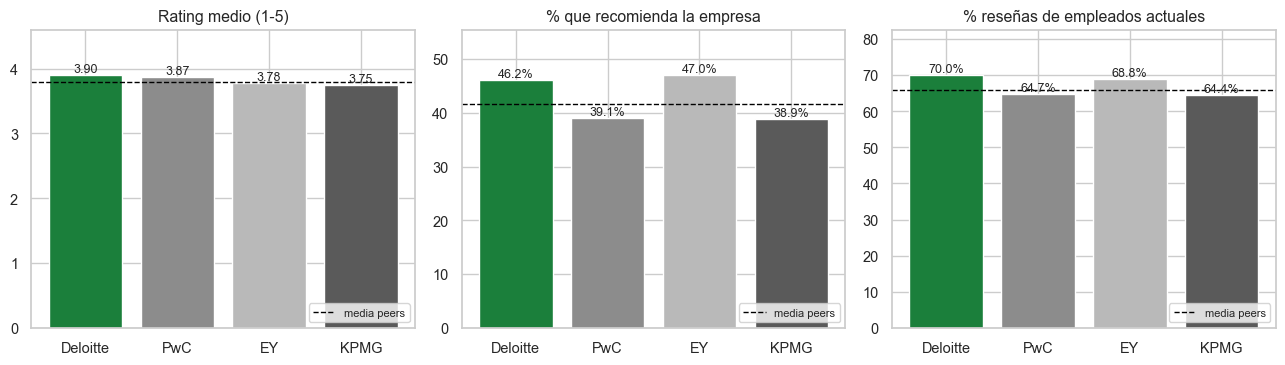

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
metricas = [('rating_medio', 'Rating medio (1-5)', '{:.2f}'), ('% recomienda (Sí)', '% que recomienda la empresa', '{:.1f}%'),
            ('% actuales', '% reseñas de empleados actuales', '{:.1f}%')]
for ax, (col, titulo, fmt) in zip(axes, metricas):
    vals = resumen.loc[FIRMS, col]
    ax.bar(vals.index, vals.values, color=[COLORES[f] for f in vals.index])
    ax.axhline(resumen.loc['Media peers', col], color='black', ls='--', lw=1, label='media peers')
    for i, v in enumerate(vals.values):
        ax.text(i, v, fmt.format(v), ha='center', va='bottom', fontsize=9)
    ax.set_title(titulo); ax.set_ylim(0, vals.max() * 1.18); ax.legend(loc='lower right', fontsize=8)
guardar(fig, '01_eda_resumen_empresas')

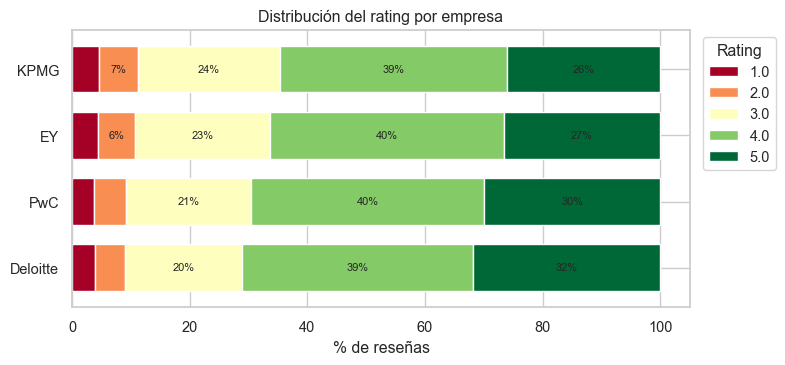

overall_rating,1.0,2.0,3.0,4.0,5.0
firm,,,,,
Deloitte,3.8,5.1,20.0,39.2,31.9
PwC,3.8,5.4,21.2,39.5,30.0
EY,4.3,6.3,23.0,39.7,26.6
KPMG,4.6,6.6,24.2,38.7,26.0


In [8]:
# Distribución completa del rating (1-5) por empresa, en %
dist = pd.crosstab(raw['firm'], raw['overall_rating'], normalize='index').loc[FIRMS] * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
dist.plot(kind='barh', stacked=True, ax=ax, colormap='RdYlGn', width=0.7)
for i, firm in enumerate(dist.index):
    acc = 0
    for r in dist.columns:
        v = dist.loc[firm, r]
        if v > 6:
            ax.text(acc + v / 2, i, f'{v:.0f}%', ha='center', va='center', fontsize=8)
        acc += v
ax.set_xlabel('% de reseñas'); ax.set_ylabel(''); ax.set_title('Distribución del rating por empresa')
ax.legend(title='Rating', bbox_to_anchor=(1.01, 1), loc='upper left')
guardar(fig, '02_eda_distribucion_rating')
dist.round(1)

**Conclusión accionable (1.1).** Deloitte es, de las cuatro, la firma mejor valorada: rating medio **3,90** frente a 3,80 de la media de peers (PwC 3,87, EY 3,78, KPMG 3,75), el menor porcentaje de reseñas de 1-2 estrellas (8,9 % vs. 10,3 %) y el segundo mayor porcentaje de recomendación sobre el total (46,2 %, solo por detrás de EY con 47,0 %; PwC y KPMG rondan el 39 %). Entre quienes opinan, Deloitte es la más recomendada (≈79 % frente a 74-78 %). Además, el 70 % de sus reseñas son de empleados actuales (66 % en los peers): la voz dominante es la de quien sigue en la firma. **Accionable:** el posicionamiento de Deloitte como "la Big Four mejor valorada por sus empleados" está respaldado por los datos y puede usarse en campus y en ofertas; como las diferencias de rating son pequeñas (0,1 puntos), el mensaje debe apoyarse en hechos concretos (secciones 4 y 6) y no solo en la nota global.

### 1.2 Empleados actuales vs. antiguos: rating y recomendación

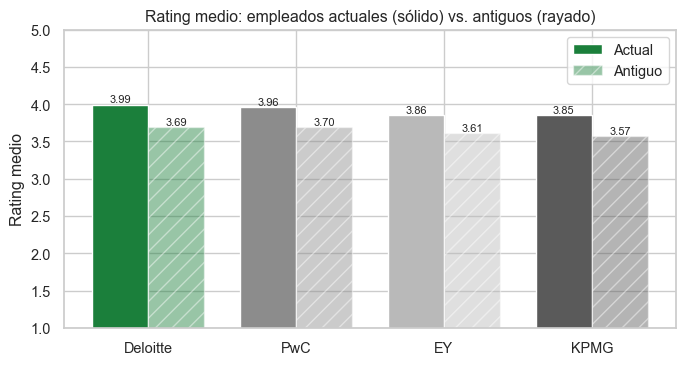

,Actual,Antiguo,gap (Actual - Antiguo),% recomienda (Actual),% recomienda (Antiguo)
firm,,,,,
Deloitte,3.99,3.69,0.31,48.01,41.83
PwC,3.96,3.70,0.26,41.53,34.53
EY,3.86,3.61,0.25,49.22,42.17
KPMG,3.85,3.57,0.28,41.52,34.05


In [9]:
tab_sit = raw.pivot_table(index='firm', columns='situacion', values='overall_rating', aggfunc='mean').loc[FIRMS]
tab_sit['gap (Actual - Antiguo)'] = tab_sit['Actual'] - tab_sit['Antiguo']
rec_sit = raw.assign(rec=(raw['recomienda'] == 'Sí') * 100).pivot_table(index='firm', columns='situacion', values='rec', aggfunc='mean').loc[FIRMS]
rec_sit.columns = [f'% recomienda ({c})' for c in rec_sit.columns]
tabla_12 = pd.concat([tab_sit, rec_sit], axis=1).round(2)

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(FIRMS)); w = 0.38
ax.bar(x - w/2, tab_sit['Actual'], w, label='Actual', color=[COLORES[f] for f in FIRMS])
ax.bar(x + w/2, tab_sit['Antiguo'], w, label='Antiguo', color=[COLORES[f] for f in FIRMS], alpha=0.45, hatch='//')
for i, f in enumerate(FIRMS):
    ax.text(x[i] - w/2, tab_sit.loc[f, 'Actual'], f"{tab_sit.loc[f, 'Actual']:.2f}", ha='center', va='bottom', fontsize=8)
    ax.text(x[i] + w/2, tab_sit.loc[f, 'Antiguo'], f"{tab_sit.loc[f, 'Antiguo']:.2f}", ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(FIRMS); ax.set_ylim(1, 5); ax.set_ylabel('Rating medio')
ax.set_title('Rating medio: empleados actuales (sólido) vs. antiguos (rayado)'); ax.legend()
guardar(fig, '03_eda_rating_actual_vs_antiguo')
tabla_12

**Conclusión accionable (1.2).** En las cuatro firmas los antiguos empleados puntúan unos 0,3 puntos menos que los actuales (Deloitte 3,99 vs. 3,69) y recomiendan 6-7 pp menos: es el sesgo de selección habitual (quien se va está más descontento), no un rasgo de Deloitte. Lo relevante es que los **antiguos empleados de Deloitte (3,69) puntúan igual o mejor que los de los peers** (PwC 3,70, EY 3,61, KPMG 3,57) y que sus actuales (3,99) son los mejor valorados del grupo. **Accionable:** como el sentimiento de quienes se van es similar en todo el sector, para entender la rotación hay que comparar los **temas** de sus cons (sección 5), no su rating.

### 1.3 Evolución del rating y de la recomendación a lo largo de la ventana temporal (2018-2023)

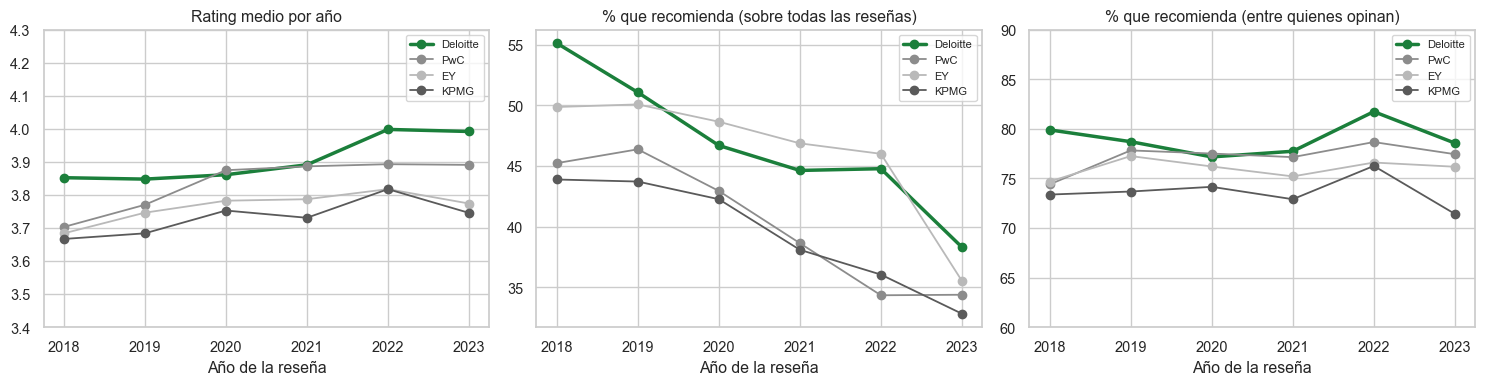

Nota: 2018 cubre solo desde julio y 2023 solo hasta marzo/abril.

Rating medio por año:
firm  Deloitte   PwC    EY  KPMG
anio                            
2018      3.85  3.70  3.68  3.67
2019      3.85  3.77  3.75  3.68
2020      3.86  3.87  3.78  3.75
2021      3.89  3.89  3.79  3.73
2022      4.00  3.89  3.82  3.82
2023      3.99  3.89  3.77  3.75

% de reseñas "sin opinión" sobre recomendar, por año (explica la caída del % que recomienda):
firm  Deloitte   PwC    EY  KPMG
anio                            
2018      31.0  39.2  33.2  40.2
2019      35.1  40.4  35.2  40.7
2020      39.5  44.6  36.2  43.0
2021      42.6  49.9  37.7  47.7
2022      45.2  56.3  39.9  52.7
2023      51.2  55.6  53.4  54.1

Reseñas por año:
firm  Deloitte    PwC     EY  KPMG
anio                              
2018      1888   1439   1544  1105
2019      5137   3730   4109  3003
2020      8722   5665   5654  4351
2021     14958  11356  10942  8970
2022      7753   9341   5714  6896
2023      1741   2027   16

In [10]:
evol = raw.groupby(['anio', 'firm']).agg(rating=('overall_rating', 'mean'),
                                        recomienda=('recomienda', lambda s: (s == 'Sí').mean() * 100),
                                        sin_opinion=('recomienda', lambda s: (s == 'Sin opinión').mean() * 100),
                                        recomienda_opina=('recomienda', lambda s: (s == 'Sí').sum() / max((s != 'Sin opinión').sum(), 1) * 100),
                                        n=('overall_rating', 'size')).reset_index()
piv_rating = evol.pivot(index='anio', columns='firm', values='rating')[FIRMS]
piv_rec = evol.pivot(index='anio', columns='firm', values='recomienda')[FIRMS]
piv_rec_op = evol.pivot(index='anio', columns='firm', values='recomienda_opina')[FIRMS]
piv_sin = evol.pivot(index='anio', columns='firm', values='sin_opinion')[FIRMS]
piv_n = evol.pivot(index='anio', columns='firm', values='n')[FIRMS]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, piv, titulo in [(axes[0], piv_rating, 'Rating medio por año'), (axes[1], piv_rec, '% que recomienda (sobre todas las reseñas)'),
                        (axes[2], piv_rec_op, '% que recomienda (entre quienes opinan)')]:
    for f in FIRMS:
        ax.plot(piv.index, piv[f], marker='o', lw=2.5 if f == TARGET else 1.3, color=COLORES[f], label=f)
    ax.set_title(titulo); ax.set_xlabel('Año de la reseña'); ax.legend(fontsize=8)
axes[0].set_ylim(3.4, 4.3); axes[2].set_ylim(60, 90)
guardar(fig, '04_eda_evolucion_rating')
print('Nota: 2018 cubre solo desde julio y 2023 solo hasta marzo/abril.\n')
print('Rating medio por año:'); print(piv_rating.round(2).to_string())
print('\n% de reseñas "sin opinión" sobre recomendar, por año (explica la caída del % que recomienda):'); print(piv_sin.round(1).to_string())
print('\nReseñas por año:'); print(piv_n.to_string())

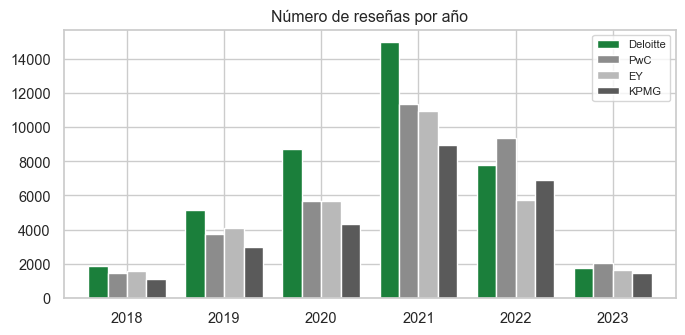

In [11]:
# Volumen de reseñas por año y empresa: ¿crece la "voz" de los empleados?
fig, ax = plt.subplots(figsize=(7, 3.5))
piv_n.plot(kind='bar', ax=ax, color=[COLORES[f] for f in FIRMS], width=0.8)
ax.set_title('Número de reseñas por año'); ax.set_xlabel(''); ax.legend(fontsize=8)
plt.xticks(rotation=0)
guardar(fig, '05_eda_volumen_anual')

**Conclusión accionable (1.3).** El rating medio de Deloitte sube de 3,85 (2018-2019) a **4,00 en 2022** y 3,99 en 2023, y desde 2022 lidera el grupo (PwC 3,89, EY 3,77-3,82, KPMG 3,75-3,82). El porcentaje que recomienda sobre el total cae en las cuatro firmas (Deloitte del 55 % al 38 %), pero es un **artefacto de la recogida de datos**: la proporción de reseñas "sin opinión" pasa del 35 % al 54 % entre 2018 y 2023. Entre quienes sí opinan, la recomendación de Deloitte es estable (78-82 %) y la más alta de las cuatro. El volumen de reseñas se triplica en 2020-2021 (hasta 15.000 reseñas de Deloitte en 2021): la "gran dimisión" también se nota en Glassdoor. **Accionable:** la tendencia es favorable; en los informes a dirección conviene usar el rating y la recomendación "entre quienes opinan", no el porcentaje bruto, para no diagnosticar una caída que no existe.

---
## 2. Sentimiento en pros y cons (control de calidad)

**Qué hacemos y por qué.** Los campos *pros* y *cons* ya llevan el sentimiento implícito: un pro debería ser positivo y un con negativo. Aplicar un clasificador de sentimiento no sirve aquí para *medir* el sentimiento sino como **control de calidad** del dato y del pipeline: si una proporción grande de pros saliera negativa, algo fallaría (modelo, truncado, limpieza) y no podríamos fiarnos del resto del análisis.

**Modelo elegido:** `distilbert-base-uncased-finetuned-sst-2-english` (Sanh et al., 2019), un transformer destilado de BERT ajustado en SST-2.

- *Justificación de negocio:* es binario (POSITIVE / NEGATIVE), que es exactamente la pregunta de control ("¿los pros suenan positivos y los cons negativos?"); una clase neutral solo añadiría ambigüedad. Es 40 % más pequeño y 60 % más rápido que BERT, lo que permite clasificar 16.000 textos en minutos incluso en CPU, y está entrenado en inglés, el idioma de las reseñas.
- *Longitud de los textos:* los modelos tipo BERT procesan un máximo de 512 tokens, por lo que se usa `truncation=True`. Como las reseñas son cortas (mediana ≈ 8-9 palabras), el truncado apenas afecta.
- Para acelerar en CPU, los textos se ordenan por longitud antes de la inferencia (menos *padding* por lote) y se restauran al orden original.

In [12]:
from transformers import pipeline

MODELO_SENT = 'distilbert-base-uncased-finetuned-sst-2-english'
cache_sent = CACHE_DIR / f'sentimiento_{TARGET}_{MAX_POR_EMPRESA}_{SEED}.parquet'

def clasificar_sentimiento(textos, clf, batch_size=64):
    """Clasifica una lista de textos; ordena por longitud para minimizar padding y devuelve en el orden original."""
    textos = list(textos)
    orden = np.argsort([len(t) for t in textos])
    res = clf([textos[i] for i in orden], batch_size=batch_size, truncation=True)
    etiquetas = np.empty(len(textos), dtype=object); scores = np.empty(len(textos))
    for pos, i in enumerate(orden):
        etiquetas[i] = res[pos]['label']; scores[i] = res[pos]['score']
    return etiquetas, scores

if USAR_CACHE and cache_sent.exists():
    sent = pd.read_parquet(cache_sent)
    print('Sentimiento cargado de caché:', cache_sent)
else:
    clf = pipeline('sentiment-analysis', model=MODELO_SENT, device=DEVICE, truncation=True, max_length=512)
    t0 = time.time()
    lab_p, sc_p = clasificar_sentimiento(df['pros'], clf)
    print(f'  pros clasificados en {time.time()-t0:.0f} s')
    lab_c, sc_c = clasificar_sentimiento(df['cons'], clf)
    print(f'  pros + cons clasificados en {time.time()-t0:.0f} s')
    sent = pd.DataFrame({'sent_pros': lab_p, 'score_pros': sc_p, 'sent_cons': lab_c, 'score_cons': sc_c}, index=df.index)
    sent.to_parquet(cache_sent)

df = df.drop(columns=[c for c in sent.columns if c in df.columns]).join(sent)
df[['firm', 'pros', 'sent_pros', 'score_pros', 'cons', 'sent_cons', 'score_cons']].head(5)

Device set to use mps


  pros clasificados en 21 s


  pros + cons clasificados en 40 s


,firm,pros,sent_pros,score_pros,cons,sent_cons,score_cons
0,Deloitte,Exposure to great opportunities and roles,POSITIVE,0.999825,No Cons i can think of,POSITIVE,0.995947
1,Deloitte,"Good exposure to business, etc",POSITIVE,0.999846,"Overtime, lots of work, very demanding, Great for anyone who is interested in business and a start off in your career. If you cannot manage the work demand/...",NEGATIVE,0.937729
2,Deloitte,Plenty of opportunities to learn,POSITIVE,0.999835,Compensation not upto the mark,NEGATIVE,0.997541
3,Deloitte,"Good culture, good salary, treated well. Opportunities to progress",POSITIVE,0.999841,Could get very busy and workload could be tough at times,NEGATIVE,0.998968
4,Deloitte,Comparatively flexible working hours (South Korea) Broad exposure to the Korean pharmaceutical and medical device industry,POSITIVE,0.985173,Unreasonable working hours without overtime pay Unrealistic project expectations and goals Lack of resources (human and market research),NEGATIVE,0.999540


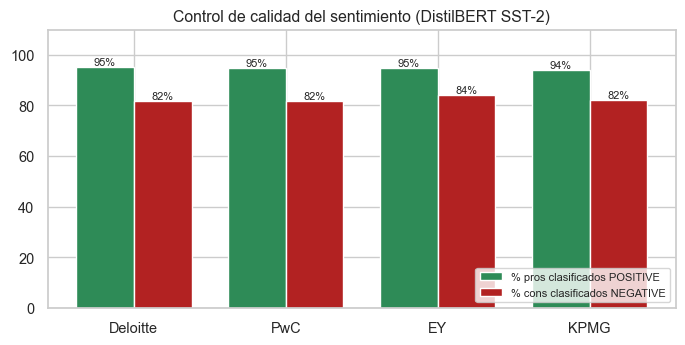

,% pros POSITIVE,% cons NEGATIVE,n
firm,,,
Deloitte,95.2,81.6,2000.0
PwC,94.8,81.8,2000.0
EY,94.8,84.1,2000.0
KPMG,94.0,82.2,2000.0
TOTAL,94.7,82.4,8000.0


In [13]:
# ---------------- Control de calidad: % de pros positivos y % de cons negativos por empresa ----------------
qc = df.groupby('firm').agg(**{
    '% pros POSITIVE': ('sent_pros', lambda s: (s == 'POSITIVE').mean() * 100),
    '% cons NEGATIVE': ('sent_cons', lambda s: (s == 'NEGATIVE').mean() * 100),
    'n': ('sent_pros', 'size')}).loc[FIRMS].round(1)
qc.loc['TOTAL'] = [(df.sent_pros == 'POSITIVE').mean() * 100, (df.sent_cons == 'NEGATIVE').mean() * 100, len(df)]

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(FIRMS)); w = 0.38
ax.bar(x - w/2, qc.loc[FIRMS, '% pros POSITIVE'], w, color='#2E8B57', label='% pros clasificados POSITIVE')
ax.bar(x + w/2, qc.loc[FIRMS, '% cons NEGATIVE'], w, color='#B22222', label='% cons clasificados NEGATIVE')
for i, f in enumerate(FIRMS):
    ax.text(x[i] - w/2, qc.loc[f, '% pros POSITIVE'], f"{qc.loc[f, '% pros POSITIVE']:.0f}%", ha='center', va='bottom', fontsize=8)
    ax.text(x[i] + w/2, qc.loc[f, '% cons NEGATIVE'], f"{qc.loc[f, '% cons NEGATIVE']:.0f}%", ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(FIRMS); ax.set_ylim(0, 110); ax.legend(loc='lower right', fontsize=8)
ax.set_title('Control de calidad del sentimiento (DistilBERT SST-2)')
guardar(fig, '06_sentimiento_qc')
qc.round(1)

In [14]:
# ¿Tiene sentido el modelo? Si funciona, los pros "negativos" y los cons "positivos" deberían asociarse a ratings distintos.
cruce = df.groupby(['sent_pros', 'sent_cons']).agg(n=('overall_rating', 'size'), rating_medio=('overall_rating', 'mean'),
                                                   pct_recomienda=('recomienda', lambda s: (s == 'Sí').mean() * 100)).round(2)
print('Rating medio según el sentimiento detectado en pros y cons:')
print(cruce.to_string())

Rating medio según el sentimiento detectado en pros y cons:
                        n  rating_medio  pct_recomienda
sent_pros sent_cons                                    
NEGATIVE  NEGATIVE    358          2.75           17.60
          POSITIVE     66          3.45           46.97
POSITIVE  NEGATIVE   6236          3.83           42.14
          POSITIVE   1340          4.21           49.93


In [15]:
# ---------------- Casos discordantes: cons clasificados como POSITIVE ----------------
pd.set_option('display.max_colwidth', 140)
disc_cons = df[df.sent_cons == 'POSITIVE'].sort_values('score_cons', ascending=False)
print(f'Cons clasificados como POSITIVE: {len(disc_cons):,} ({len(disc_cons)/len(df)*100:.1f}%)')
print('\n-- Los 12 con mayor confianza del modelo:')
display(disc_cons[['firm', 'cons', 'score_cons', 'overall_rating']].head(12))
print('\n-- 8 ejemplos aleatorios (semilla 42):')
display(disc_cons.sample(8, random_state=SEED)[['firm', 'cons', 'score_cons', 'overall_rating']])

Cons clasificados como POSITIVE: 1,406 (17.6%)

-- Los 12 con mayor confianza del modelo:


,firm,cons,score_cons,overall_rating
7851,PwC,Great learning and amazing support from partners,0.999887,4.0
833,Deloitte,"No cons, so far I love it!",0.999886,5.0
5283,KPMG,good learning experience fun challenging rewarding,0.999884,5.0
2373,EY,Great place i love it so much,0.999883,4.0
436,Deloitte,All good great culture and environment,0.999883,5.0
6437,PwC,wonderful excellent good wow exemplery,0.999882,5.0
4976,KPMG,Great Work and life balance,0.999881,4.0
2814,EY,"great company, good travel rate, good everything",0.999879,5.0
7363,PwC,"Amazing projects, good networking, helpful career development",0.999878,4.0
287,Deloitte,This is a good company,0.999878,1.0



-- 8 ejemplos aleatorios (semilla 42):


,firm,cons,score_cons,overall_rating
1404,Deloitte,long working hours. A lot depends on your partner.,0.936858,4.0
6856,PwC,"working hours are high, everyone know",0.954887,3.0
607,Deloitte,"Work-life balance, Bonuses, Gender stereotypes, Hike and Training",0.992419,4.0
5933,KPMG,"No concern, good work environment",0.997093,5.0
3565,EY,Prolonging growth and long working hours,0.720217,4.0
3898,EY,Work life balance Pressure High expectations Work never leaves Leaves,0.998413,3.0
565,Deloitte,All of the benefits can go for a toss if your team works differently. Culture is largely team specific,0.973279,3.0
570,Deloitte,Long hours and challenging work.,0.999709,5.0


In [16]:
# ---------------- Casos discordantes: pros clasificados como NEGATIVE ----------------
disc_pros = df[df.sent_pros == 'NEGATIVE'].sort_values('score_pros', ascending=False)
print(f'Pros clasificados como NEGATIVE: {len(disc_pros):,} ({len(disc_pros)/len(df)*100:.1f}%)')
print('\n-- Los 12 con mayor confianza del modelo:')
display(disc_pros[['firm', 'pros', 'score_pros', 'overall_rating']].head(12))
print('\n-- 8 ejemplos aleatorios (semilla 42):')
display(disc_pros.sample(8, random_state=SEED)[['firm', 'pros', 'score_pros', 'overall_rating']])
print('\nLongitud media (palabras) de los pros negativos vs. el resto:',
      round(disc_pros.pros_n_palabras.mean(), 1), 'vs', round(df[df.sent_pros == 'POSITIVE'].pros_n_palabras.mean(), 1))

Pros clasificados como NEGATIVE: 424 (5.3%)

-- Los 12 con mayor confianza del modelo:


,firm,pros,score_pros,overall_rating
7806,PwC,-learning a lot - flat organisation,0.999812,3.0
7480,PwC,"Worst Company, Worst Culture, HR's liars, Huge Work Pressure, Worst kind of Unprofessionals.",0.999812,1.0
7625,PwC,"Flat management structure, no much Hierarchies.",0.999807,4.0
815,Deloitte,Poor work life balance and deterimental to your career,0.999805,2.0
9,Deloitte,Not a good company to work at,0.999794,1.0
469,Deloitte,No pros. They are not doing anything good,0.999792,1.0
1346,Deloitte,Nothing good to speak of.,0.999779,1.0
70,Deloitte,"Nothing comes to mind, just avoid working in their Internal Client Services division",0.999778,1.0
3753,EY,Busy Season as bad as it gets - hard to find people who aren't kind and helpful,0.999776,5.0
2435,EY,Nothing good in this firm,0.999774,1.0



-- 8 ejemplos aleatorios (semilla 42):


,firm,pros,score_pros,overall_rating
5222,KPMG,Reputable company name on resume,0.995499,3.0
76,Deloitte,steep learning curve; you learn a lot in a very short amount of period,0.961817,4.0
5308,KPMG,"it has the brand name of KPMG if you love Big Boss show and unfortunately you can not participant in it, then join this company :)",0.992798,2.0
1891,Deloitte,"Money, location, clients, office, kudos.",0.816857,2.0
872,Deloitte,Work culture is good balance is maintained Not much pressure at work Policies are great,0.524307,3.0
3688,EY,Nothing is pros inside this company for assurance consultant,0.999202,3.0
836,Deloitte,"There is nothing to say here Judging from their allegations against me, I dare not say anything baseless that could err potentially here.",0.996485,1.0
3883,EY,Good Project in PI. Risk and Internal Audit is screwed up,0.996168,3.0



Longitud media (palabras) de los pros negativos vs. el resto: 12.7 vs 10.1


**Lectura de los casos discordantes.** El control de calidad se supera: el **94,7 % de los pros** se clasifican como positivos y el **82,4 % de los cons** como negativos, con cifras casi idénticas en las cuatro firmas (pros 94-95 %, cons 82-84 %), lo que indica que ni la limpieza ni el truncado distorsionan el texto. El modelo además "entiende" las reseñas: quienes tienen pros y cons negativos puntúan 2,75 de media, frente a 4,21 cuando ambos son positivos.

Los **cons clasificados como positivos (17,6 %)** son de tres tipos: (1) *ausencia de queja* — "No cons, so far I love it!", "No concern, good work environment" —, que el modelo clasifica bien (son positivos) y que en el topic modeling se tratan aparte como *Sin contenido*; (2) *listas de temas sin polaridad* — "Work-life balance, Bonuses, Hike and Training" —, donde el empleado enumera de qué se queja sin usar palabras negativas y el modelo, que no sabe que está leyendo un "con", las lee como neutras o positivas; y (3) *quejas aceptadas con deportividad* — "Long hours and challenging work" con rating 5 —, muy propias de las Big Four, donde las horas se asumen como parte del trato. Los **pros clasificados como negativos (5,3 %)** son, sobre todo: (1) *pros que no son pros* — "Nothing good to speak of", "Worst company" —, reseñas de 1 estrella que niegan que exista algo positivo; (2) *elogios con doble filo o con jerga* — "steep learning curve", "flat organisation, not much hierarchy", "Not much pressure at work" —, donde las negaciones y las expresiones técnicas confunden a un modelo entrenado con críticas de cine; y (3) pros largos con matices y críticas intercaladas (los pros negativos tienen 12,7 palabras de media frente a 10,1).

En conjunto, los casos discordantes no revelan un fallo del pipeline sino los límites de un clasificador binario sin contexto, y justifican dos decisiones posteriores: separar las reseñas sin contenido antes de modelar y comparar empresas por **temática**, no por sentimiento.

---
## 3. Topic modeling con BERTopic

**Por qué BERTopic y no LDA.** Las reseñas son textos muy cortos (mediana ≈ 8 palabras) y LDA, basado en bolsa de palabras, funciona mal con documentos cortos y vocabulario variado ("WLB", "work life balance", "long hours" son el mismo tema). BERTopic (Grootendorst, 2022) agrupa por **significado** usando embeddings de un transformer de frases, reduce la dimensión con **UMAP**, agrupa con **HDBSCAN** y describe cada grupo con **c-TF-IDF** (palabras que distinguen a un topic de los demás). Permite además decidir qué hacer con los documentos que no encajan en ningún grupo (outliers).

**Regla de comparabilidad.** Se entrena **un único modelo para los pros y otro para los cons con las reseñas de las cuatro firmas juntas**. Si se entrenara un modelo por empresa, los topics no coincidirían y no se podrían comparar los porcentajes.

**Parámetros y justificación de negocio**

| Componente | Elección | Por qué |
|---|---|---|
| Embeddings | `all-MiniLM-L6-v2` (sentence-transformers) | Modelo de frases rápido y preciso en inglés para textos cortos; permite calcular 16.000 embeddings en minutos en CPU. |
| UMAP | `n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42` | Valores recomendados por el autor de BERTopic; la semilla hace el resultado reproducible. |
| HDBSCAN | `min_cluster_size=60, min_samples=10, cluster_selection_method='eom'` | Un topic debe tener al menos ~60 reseñas (0,75 % de 8.000) para que RRHH lo considere un patrón y no anécdotas; `min_samples` bajo reduce el número de outliers. |
| Vectorizador c-TF-IDF | unigramas y bigramas, *stopwords* en inglés + nombres de las firmas y palabras vacías de opinión ("good", "great", "company"...) | Que las palabras clave describan el **tema**, no la valoración ni la empresa. |
| Representación | Maximal Marginal Relevance (`diversity=0.3`) | Palabras clave menos redundantes y más legibles para RRHH. |

**Reseñas sin contenido.** Antes de modelar separo los textos que no dicen nada ("none", "nothing", "no cons", "can't think of any"...). No tiene sentido forzarlos a un tema; además, un con "nothing" es en realidad una señal positiva (el empleado no encuentra pegas) y se reporta aparte como categoría *Sin contenido*.

In [17]:
# ---------------- Detección de textos sin contenido ----------------
PATRON_VACIO = re.compile(
    r"^(no|none|nothing|nil|nope|na|n a|not much|nothing much|nothing really|not really|none really|nothing specific|nothing major|"
    r"nothing bad|nothing so far|nothing at all|nothing in particular|nothing special|nothing comes to mind|no cons|no complaints|"
    r"no issues|no negatives|no comment|no comments|no downsides|no problems|nothing negative|nothing to (say|add|report|mention|note|complain about|share)|"
    r"(i )?(can ?not|cant|can t|could ?not|couldnt|could t|dont|don t|do not) (think|recall|remember) (of )?(any|anything|one|many|much|some)( cons| negatives| right now| at the moment| so far| at this time)?|"
    r"none (that |which )?i can think of|nothing (that |which )?i can think of( of)?|none (i )?can think of|there (are|is) no(ne| cons| con| downsides| negatives)|i have no (cons|complaints|issues)|"
    r"all good|everything is (good|great|fine|ok)|cannot think of anything|not applicable|nothing to dislike|no dislikes)"
    r"( (yet|so far|really|at all|now|right now|to be honest|honestly|that i can think of|i can think of|at the moment|for now|as such))*$")

def sin_contenido(texto):
    t = re.sub(r"[^a-z ]", " ", str(texto).lower())
    t = re.sub(r"\s+", " ", t).strip()
    if t == '' or len(t) <= 1:
        return True
    return bool(PATRON_VACIO.match(t))

for col in ['pros', 'cons']:
    df[f'{col}_vacio'] = df[col].map(sin_contenido)

vac = df.groupby('firm')[['pros_vacio', 'cons_vacio']].mean().loc[FIRMS] * 100
vac.columns = ['% pros sin contenido', '% cons sin contenido']
print(vac.round(1).to_string())
print('\nEjemplos de cons detectados como "sin contenido":')
print(df[df.cons_vacio].cons.sample(15, random_state=SEED).tolist())

          % pros sin contenido  % cons sin contenido
firm                                                
Deloitte                   0.0                   1.2
PwC                        0.0                   1.0
EY                         0.0                   0.8
KPMG                       0.0                   1.0

Ejemplos de cons detectados como "sin contenido":
["I can't think of any", 'No Cons i can think of', 'none that I can think of', "Can't think of any cons", 'I cant think of any cons', 'None I can think of.', 'nothing I can think of right now', 'Nothing at all so far', 'I cannot think of any cons', 'Nothing that I can think of.', '1 2 3 4 5', 'None that I can think of', 'Nothing I can think of at the moment', 'None that I can think of', 'None that I can think of']


In [18]:
from sentence_transformers import SentenceTransformer

MODELO_EMB = 'all-MiniLM-L6-v2'
emb_model = SentenceTransformer(MODELO_EMB, device=DEVICE)

def obtener_embeddings(textos, nombre):
    """Calcula (o carga de caché) los embeddings normalizados de una lista de textos."""
    f = CACHE_DIR / f'emb_{nombre}_{TARGET}_{MAX_POR_EMPRESA}_{SEED}.npy'
    if USAR_CACHE and f.exists():
        e = np.load(f)
        if len(e) == len(textos):
            print(f'Embeddings {nombre} cargados de caché'); return e
    t0 = time.time()
    e = emb_model.encode(list(textos), batch_size=128, show_progress_bar=False, normalize_embeddings=True)
    np.save(f, e)
    print(f'Embeddings {nombre}: {e.shape} en {time.time()-t0:.0f} s')
    return e

# Documentos a modelar: solo los que tienen contenido
idx_pros = df.index[~df.pros_vacio]; docs_pros = df.loc[idx_pros, 'pros'].tolist()
idx_cons = df.index[~df.cons_vacio]; docs_cons = df.loc[idx_cons, 'cons'].tolist()
emb_pros = obtener_embeddings(docs_pros, 'pros')
emb_cons = obtener_embeddings(docs_cons, 'cons')

Embeddings pros: (7998, 384) en 10 s


Embeddings cons: (7921, 384) en 8 s


In [19]:
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from bertopic.representation import MaximalMarginalRelevance
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

# Stopwords: inglés + nombres de las firmas + palabras de valoración que no describen el tema
STOP_EXTRA = {'deloitte', 'pwc', 'ey', 'kpmg', 'big', 'four', 'big4', 'firm', 'firms', 'company', 'companies', 'organisation', 'organization',
              'good', 'great', 'best', 'nice', 'bad', 'worst', 'poor', 'excellent', 'amazing', 'awesome', 'really', 'very', 'lot', 'lots',
              'like', 'just', 'also', 'etc', 'things', 'thing', 'way', 'get', 'got', 'sometimes', 'quite', 'pretty', 'much', 'many',
              'overall', 'ok', 'okay', 'cons', 'pros', 'con', 'pro', 'better', 'worse', 'high', 'low', 'does', 'doesn', 'don', 'isn', 'aren',
              'wasn', 'didn', 'wouldn', 'couldn', 'll', 've', 'especially', 'definitely', 'highly', 'extremely', 'super', 'bit', 'little',
              'usi', 'india', 'uk', 'us', 'london'}
STOPWORDS = list(ENGLISH_STOP_WORDS.union(STOP_EXTRA))

MIN_CLUSTER = 60

def construir_bertopic(seed=SEED, min_cluster_size=MIN_CLUSTER):
    umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=seed)
    hdbscan_model = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=10, metric='euclidean',
                            cluster_selection_method='eom', prediction_data=True)
    vectorizer_model = CountVectorizer(stop_words=STOPWORDS, ngram_range=(1, 2), min_df=5)
    ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)
    representation_model = MaximalMarginalRelevance(diversity=0.3)
    return BERTopic(embedding_model=emb_model, umap_model=umap_model, hdbscan_model=hdbscan_model,
                    vectorizer_model=vectorizer_model, ctfidf_model=ctfidf_model,
                    representation_model=representation_model, top_n_words=10, calculate_probabilities=False, verbose=False)

t0 = time.time()
tm_pros = construir_bertopic()
topics_pros_orig, _ = tm_pros.fit_transform(docs_pros, embeddings=emb_pros)
print(f'Modelo PROS: {len(set(topics_pros_orig)) - (1 if -1 in topics_pros_orig else 0)} topics, '
      f'{np.mean(np.array(topics_pros_orig) == -1)*100:.1f}% outliers, {time.time()-t0:.0f} s')

t0 = time.time()
tm_cons = construir_bertopic()
topics_cons_orig, _ = tm_cons.fit_transform(docs_cons, embeddings=emb_cons)
print(f'Modelo CONS: {len(set(topics_cons_orig)) - (1 if -1 in topics_cons_orig else 0)} topics, '
      f'{np.mean(np.array(topics_cons_orig) == -1)*100:.1f}% outliers, {time.time()-t0:.0f} s')

Modelo PROS: 33 topics, 24.5% outliers, 38 s


Modelo CONS: 30 topics, 24.6% outliers, 17 s


### 3.1 Tratamiento de los outliers

HDBSCAN deja fuera de todo topic (etiqueta `-1`) a las reseñas que no están en una zona densa del espacio de embeddings. **Decisión:** reasignar cada outlier al topic cuyo *embedding* medio es más parecido (`reduce_outliers(strategy='embeddings')`).

*Justificación de negocio:* el objetivo es comparar **porcentajes de reseñas por categoría entre empresas**. Si dejáramos fuera un tercio de las reseñas, los porcentajes solo reflejarían las opiniones más "prototípicas" y largas, y una empresa cuyos empleados escriben de forma más variada quedaría infrarrepresentada. Las reseñas realmente vacías ya se han apartado antes (*Sin contenido*), así que todo outlier restante tiene un tema del que habla, aunque lo exprese de forma poco frecuente. Más abajo (sección 4) se comprueba que las conclusiones son robustas: los porcentajes por categoría apenas cambian si se calculan solo con las reseñas asignadas originalmente.

In [20]:
def reasignar_outliers(tm, docs, topics, emb):
    nuevos = tm.reduce_outliers(docs, topics, strategy='embeddings', embeddings=emb)
    tm.update_topics(docs, topics=nuevos, vectorizer_model=CountVectorizer(stop_words=STOPWORDS, ngram_range=(1, 2), min_df=5),
                     ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
                     representation_model=MaximalMarginalRelevance(diversity=0.3))
    return nuevos

# % de outliers por empresa ANTES de reasignar (para documentar la decisión)
df['topic_pros_orig'] = pd.Series(topics_pros_orig, index=idx_pros)
df['topic_cons_orig'] = pd.Series(topics_cons_orig, index=idx_cons)
outl = pd.DataFrame({'% outliers pros': df.loc[idx_pros].groupby('firm')['topic_pros_orig'].apply(lambda s: (s == -1).mean() * 100),
                     '% outliers cons': df.loc[idx_cons].groupby('firm')['topic_cons_orig'].apply(lambda s: (s == -1).mean() * 100)}).loc[FIRMS]
print('Outliers antes de la reasignación:'); print(outl.round(1).to_string())

topics_pros = reasignar_outliers(tm_pros, docs_pros, topics_pros_orig, emb_pros)
topics_cons = reasignar_outliers(tm_cons, docs_cons, topics_cons_orig, emb_cons)
df['topic_pros'] = pd.Series(topics_pros, index=idx_pros)
df['topic_cons'] = pd.Series(topics_cons, index=idx_cons)
print(f'\nOutliers tras la reasignación: pros {np.mean(np.array(topics_pros) == -1)*100:.1f}% | cons {np.mean(np.array(topics_cons) == -1)*100:.1f}%')

2026-10-11 19:20:15,308 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers antes de la reasignación:
          % outliers pros  % outliers cons
firm                                      
Deloitte             24.3             27.3
PwC                  25.6             24.1
EY                   22.7             23.8
KPMG                 25.4             23.3


2026-10-11 19:20:18,026 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.



Outliers tras la reasignación: pros 0.0% | cons 0.0%


### 3.2 Topics obtenidos (palabras clave y reseñas representativas)

In [21]:
def tabla_topics(tm, topics, n_palabras=8):
    info = tm.get_topic_info()
    info = info[info.Topic != -1].copy()
    info['Palabras clave'] = info['Topic'].map(lambda t: ', '.join(w for w, _ in tm.get_topic(t)[:n_palabras]))
    info['%'] = info['Count'] / len(topics) * 100
    return info[['Topic', 'Count', '%', 'Palabras clave']].round(1)

def mostrar_ejemplos(tm, docs, topics, n_docs=3):
    """Imprime, por topic, las reseñas más representativas (centroide) para la revisión manual."""
    info = tm.get_topic_info()
    for t in info[info.Topic != -1].Topic:
        reps = tm.get_representative_docs(t) or []
        print(f'\n[Topic {t}] {", ".join(w for w, _ in tm.get_topic(t)[:6])}')
        for r in reps[:n_docs]:
            print('   •', r[:150])

tabla_pros = tabla_topics(tm_pros, topics_pros)
print(f'PROS: {len(tabla_pros)} topics')
display(tabla_pros)

PROS: 33 topics


,Topic,Count,%,Palabras clave
0,0,607,7.6,"work culture, culture work, working culture, culture benefits, opportunities culture, culture environment, opportunities work, work life"
1,1,754,9.4,"career path, learning experience, clear career, career growth, career, skills, career progression, opportunities career"
2,2,524,6.6,"team, teams, team work, team members, teammates, teamwork, coaching, team support"
3,3,468,5.9,"clients, exposure clients, client exposure, client base, consultant, client facing, work clients, variety clients"
4,4,396,5.0,"work place, place learn, start career, school, work people, career, finance, work job"
5,5,402,5.0,"environment people, work environment, environment work, working environment, friendly environment, professional environment, office peop..."
6,6,344,4.3,"balance work, work life, benefits work, balance benefits, pay work, salary work, flexibility work, work load"
7,7,479,6.0,"salary benefits, competitive salary, salaries, salary package, salary bonus, perks, decent salary, competitive pay"
8,8,319,4.0,"flexible working, working hours, flexible work, flexible hours, work flexible, working arrangements, maternity, work flexibility"
9,9,308,3.9,"exposure, different industries, exposure learning, exposure various, experience exposure, opportunities exposure, learning exposure, wor..."


In [22]:
mostrar_ejemplos(tm_pros, docs_pros, topics_pros, n_docs=3)


[Topic 0] work culture, culture work, working culture, culture benefits, opportunities culture, culture environment
   • Nice work.culture and work.life balance
   • Good work culture and work life balance
   • Good to work culture, work life balance.

[Topic 1] career path, learning experience, clear career, career growth, career, skills
   • Everyone here makes you feel as if you belong. You work hard but there are a lot of perks. This is not your typical law office. I'm fairly new and I s
   • Clear career path, good learning opportunity
   • Learning opportunities and clear career path

[Topic 2] team, teams, team work, team members, teammates, teamwork
   • Very good team and good culture, supportive bosses and team members
   • team work, team spirit. culture
   • flatter teams resulting in better team work

[Topic 3] clients, exposure clients, client exposure, client base, consultant, client facing
   • - Exposure to a middle market and blue chip clients - Possibility to know a

In [23]:
tabla_cons = tabla_topics(tm_cons, topics_cons)
print(f'CONS: {len(tabla_cons)} topics')
display(tabla_cons)

CONS: 30 topics


,Topic,Count,%,Palabras clave
0,0,850,10.7,"work long, weekends, working hours, work hours, hours working, hours stressful, hectic, hours work"
1,1,446,5.6,"balance work, work life, life balance, maintain work, balance hard, worklife, worklife balance, manage work"
2,2,381,4.8,"busy season, season, hours busy, seasons, peak season, balance busy, work busy, long working"
3,3,431,5.4,"hours pay, hours salary, salary long, pay hours, work hours, working hours, work long, pay work"
4,4,360,4.5,"say, negative, complain, started, comment, date, moment, happy"
5,5,376,4.7,"projects, projects work, depending project, technologies, development, projects long, impact, switch"
6,6,470,5.9,"salary compared, salary competitive, industry salary, pay compared, competitive salary, pay market, pay competitive, compared industry"
7,7,352,4.4,"bureaucracy, hierarchy, corporate, red tape, flexibility, bureaucratic, mobility, internal"
8,8,264,3.3,"hours work, hectic work, balance hours, life balance, work life, balance work, work work, stressful work"
9,9,278,3.5,"client, consulting, clients, consultants, consultant, client facing, engagement, partner"


In [24]:
mostrar_ejemplos(tm_cons, docs_cons, topics_cons, n_docs=3)


[Topic 0] work long, weekends, working hours, work hours, hours working, hours stressful
   • Long working hours and sometimes stressful
   • Long working hours Sometimes can become stressful
   • Long working hours, weekends working.

[Topic 1] balance work, work life, life balance, maintain work, balance hard, worklife
   • Balance between work and life
   • Bad work-life balance to work here
   • No work life balance and not so great work cluture

[Topic 2] busy season, season, hours busy, seasons, peak season, balance busy
   • Long hours at busy season but balanced with tone in lieu
   • long hours during busy season
   • long hours during busy season

[Topic 3] hours pay, hours salary, salary long, pay hours, work hours, working hours
   • Horrible insurance - my new company's insurance is 1/5th the cost with 5x the coverage. Relocating is nearly impossible. Rotating to other teams is al
   • - Slow promotion (assumed you get promotion every year) - Management refused to book ti

### 3.3 Agrupación de los topics en categorías de negocio

Los topics se agrupan **a mano**, tras leer sus palabras clave y sus reseñas representativas, en categorías que RRHH puede accionar. Se usan **las mismas categorías para pros y para cons**, de modo que después se pueda calcular el balance neto por categoría.

| Categoría | Qué incluye |
|---|---|
| Compensación y beneficios | Salario, bonus, subidas, beneficios, seguro médico, pensión |
| Conciliación y carga de trabajo | Horas, work-life balance, presión, estrés, *busy season*, burnout |
| Carrera, formación y desarrollo | Aprendizaje, formación, promoción, progresión, oportunidades, certificaciones |
| Dirección y management | Jefes, managers, *partners*, liderazgo, comunicación, reconocimiento |
| Cultura y compañeros | Ambiente, equipo, compañeros, diversidad, inclusión, valores |
| Burocracia, procesos y política interna | Jerarquía, política interna, procesos, herramientas, tamaño de la organización, favoritismos |
| Flexibilidad y teletrabajo | Trabajo remoto/híbrido, horarios flexibles, vacaciones, desplazamientos |
| Marca, clientes y proyectos | Prestigio de la firma, clientes, variedad y calidad de los proyectos, exposición |
| Otros | Topics que no encajan de forma clara en ninguna categoría (se revisan en la tabla) |

**Notas de la revisión manual.**
- En los pros, el topic 18 ("say, far, share, review...") agrupa textos que en realidad dicen que *no hay* pros ("None. Bad experience overall"); se trata como *Sin contenido*. En los cons, los topics 4 ("Cannot think of any negative") y 10 ("No major cons") son el equivalente y también van a *Sin contenido*.
- Topics mixtos: el topic 0 de pros mezcla "work culture" y "work life balance"; se asigna a *Cultura* porque la cultura domina las palabras clave. Los topics 3 y 15 de cons mezclan salario y horas ("low salary for high hours", "work life balance, pay scale"); se asignan a *Compensación* porque es la palabra que los distingue de los topics puros de horas (0, 1, 2, 8, 13).
- Los topics 29 y 32 de pros y 22 y 24 de cons son reseñas largas que mezclan varios temas sin uno dominante; se dejan en *Otros* en lugar de forzar una categoría.
- **Robustez entre máquinas.** Los números de topic pueden cambiar si se ejecuta con otra GPU o versiones distintas de las librerías. La celda siguiente guarda la primera palabra clave de cada topic en el momento de la revisión y comprueba que sigue coincidiendo; si cambian más del 20 % de los topics, avisa y usa una asignación automática por léxico (definida más abajo) que replica la lógica de la revisión manual.

In [25]:
CATEGORIAS = ['Compensación y beneficios', 'Conciliación y carga de trabajo', 'Carrera, formación y desarrollo',
              'Dirección y management', 'Cultura y compañeros', 'Burocracia, procesos y política interna',
              'Flexibilidad y teletrabajo', 'Marca, clientes y proyectos', 'Otros']
SIN_CONTENIDO = 'Sin contenido'

# Asignación manual topic -> categoría (revisada leyendo palabras clave y reseñas representativas)
CATEGORIA_PROS = {
    0: 'Cultura y compañeros',  # work culture
    1: 'Carrera, formación y desarrollo',  # career path
    2: 'Cultura y compañeros',  # team
    3: 'Marca, clientes y proyectos',  # clients
    4: 'Carrera, formación y desarrollo',  # work place
    5: 'Cultura y compañeros',  # environment people
    6: 'Conciliación y carga de trabajo',  # balance work
    7: 'Compensación y beneficios',  # salary benefits
    8: 'Flexibilidad y teletrabajo',  # flexible working
    9: 'Carrera, formación y desarrollo',  # exposure
    10: 'Carrera, formación y desarrollo',  # work benefits
    11: 'Marca, clientes y proyectos',  # brand value
    12: 'Marca, clientes y proyectos',  # different projects
    13: 'Cultura y compañeros',  # compared
    14: 'Cultura y compañeros',  # inclusive
    15: 'Carrera, formación y desarrollo',  # accounting
    16: 'Cultura y compañeros',  # colleagues
    17: 'Cultura y compañeros',  # work people
    18: SIN_CONTENIDO,  # say
    19: 'Cultura y compañeros',  # work smart
    20: 'Flexibilidad y teletrabajo',  # work home
    21: 'Carrera, formación y desarrollo',  # opportunities people
    22: 'Dirección y management',  # leadership
    23: 'Carrera, formación y desarrollo',  # upskill
    24: 'Carrera, formación y desarrollo',  # resume
    25: 'Carrera, formación y desarrollo',  # training
    26: 'Marca, clientes y proyectos',  # international
    27: 'Dirección y management',  # seniors
    28: 'Compensación y beneficios',  # benefits benefits
    29: 'Otros',  # beneficial
    30: 'Carrera, formación y desarrollo',  # environment learn
    31: 'Compensación y beneficios',  # summer
    32: 'Otros',  # years
}
CATEGORIA_CONS = {
    0: 'Conciliación y carga de trabajo',  # work long
    1: 'Conciliación y carga de trabajo',  # balance work
    2: 'Conciliación y carga de trabajo',  # busy season
    3: 'Compensación y beneficios',  # hours pay
    4: SIN_CONTENIDO,  # say
    5: 'Marca, clientes y proyectos',  # projects
    6: 'Compensación y beneficios',  # salary compared
    7: 'Burocracia, procesos y política interna',  # bureaucracy
    8: 'Conciliación y carga de trabajo',  # hours work
    9: 'Marca, clientes y proyectos',  # client
    10: SIN_CONTENIDO,  # major
    11: 'Conciliación y carga de trabajo',  # overtime work
    12: 'Dirección y management',  # team members
    13: 'Conciliación y carga de trabajo',  # workload
    14: 'Compensación y beneficios',  # compensation
    15: 'Compensación y beneficios',  # balance salary
    16: 'Carrera, formación y desarrollo',  # promotions
    17: 'Cultura y compañeros',  # culture
    18: 'Conciliación y carga de trabajo',  # pressure
    19: 'Flexibilidad y teletrabajo',  # travel
    20: 'Burocracia, procesos y política interna',  # political
    21: 'Carrera, formación y desarrollo',  # career
    22: 'Otros',  # audit
    23: 'Compensación y beneficios',  # salary compared
    24: 'Otros',  # place work
    25: 'Dirección y management',  # management
    26: 'Conciliación y carga de trabajo',  # deadlines
    27: 'Dirección y management',  # seniors
    28: 'Cultura y compañeros',  # work culture
    29: 'Dirección y management',  # lack work
}

# ---------------- Asignación automática por léxico (respaldo y validación de la revisión manual) ----------------
LEXICO = {
    'Compensación y beneficios': {'salary', 'salaries', 'pay', 'paid', 'compensation', 'bonus', 'bonuses', 'benefits', 'underpaid', 'pension',
                                  '401k', 'insurance', 'perks', 'hike', 'hikes', 'pto', 'holidays', 'allowance', 'reimbursement', 'incentives'},
    'Conciliación y carga de trabajo': {'hours', 'balance', 'life', 'overtime', 'workload', 'workloads', 'weekends', 'busy', 'season', 'seasons',
                                        'pressure', 'stress', 'stressful', 'deadlines', 'hectic', 'long', 'worklife'},
    'Carrera, formación y desarrollo': {'career', 'learning', 'learn', 'training', 'trainings', 'growth', 'promotion', 'promotions', 'promoted',
                                        'progression', 'opportunities', 'opportunity', 'development', 'upskill', 'certifications', 'skills',
                                        'mentorship', 'appraisal', 'start', 'grow', 'advancement', 'exposure'},
    'Dirección y management': {'management', 'managers', 'manager', 'leadership', 'leaders', 'partners', 'partner', 'seniors', 'senior', 'hr',
                               'supervisor', 'directors', 'upper', 'staffs', 'communication'},
    'Cultura y compañeros': {'culture', 'people', 'team', 'teams', 'teammates', 'teamwork', 'colleagues', 'environment', 'friendly', 'inclusive',
                             'diversity', 'inclusion', 'toxic', 'smart', 'collaborative', 'helpful', 'supportive'},
    'Burocracia, procesos y política interna': {'bureaucracy', 'bureaucratic', 'hierarchy', 'politics', 'political', 'red', 'tape', 'corporate',
                                                'processes', 'process', 'transparency', 'bias', 'internal', 'favouritism'},
    'Flexibilidad y teletrabajo': {'flexible', 'flexibility', 'remote', 'home', 'travel', 'hybrid', 'commute', 'schedules', 'arrangements', 'wfh'},
    'Marca, clientes y proyectos': {'brand', 'branding', 'clients', 'client', 'projects', 'project', 'reputation', 'resume', 'cv', 'international',
                                    'multinational', 'global', 'globally', 'consulting', 'variety', 'industries', 'engagement', 'overseas'},
    SIN_CONTENIDO: {'negative', 'complain', 'major', 'significant', 'downsides', 'dislike', 'complaints'},
}

def categoria_automatica(tm, t, n=10):
    puntos = {c: 0.0 for c in LEXICO}
    for palabra, peso in tm.get_topic(t)[:n]:
        for tok in palabra.split():
            for c, lex in LEXICO.items():
                if tok in lex:
                    puntos[c] += peso
    mejor = max(puntos, key=puntos.get)
    return mejor if puntos[mejor] > 0 else 'Otros'

def comprobar_y_elegir_mapa(tm, mapa_manual, firmas, nombre):
    """Si los topics ya no coinciden con los revisados a mano (otra máquina), usa la asignación automática."""
    auto = {t: categoria_automatica(tm, t) for t in tm.get_topics() if t != -1}
    cambiados = [t for t, w in firmas.items() if t not in auto or w not in [p for p, _ in tm.get_topic(t)[:10]]]
    acuerdo = np.mean([auto[t] == mapa_manual.get(t, 'Otros') for t in auto]) * 100
    print(f'{nombre}: {len(auto)} topics | topics cuya firma ha cambiado: {len(cambiados)} | acuerdo regla automática vs. revisión manual: {acuerdo:.0f}%')
    if len(cambiados) > 0.2 * len(firmas):
        print(f'  AVISO: los topics de {nombre} no coinciden con los revisados a mano; se usa la asignación automática por léxico.')
        return auto
    return mapa_manual

# Primera palabra clave de cada topic cuando se hizo la revisión manual (detecta cambios entre máquinas)
FIRMA_PROS = {0: 'work culture', 1: 'career path', 2: 'team', 3: 'clients', 4: 'work place', 5: 'environment people', 6: 'balance work', 7: 'salary benefits', 8: 'flexible working', 9: 'exposure', 10: 'work benefits', 11: 'brand value', 12: 'different projects', 13: 'compared', 14: 'inclusive', 15: 'accounting', 16: 'colleagues', 17: 'work people', 18: 'say', 19: 'work smart', 20: 'work home', 21: 'opportunities people', 22: 'leadership', 23: 'upskill', 24: 'resume', 25: 'training', 26: 'international', 27: 'seniors', 28: 'benefits benefits', 29: 'beneficial', 30: 'environment learn', 31: 'summer', 32: 'years'}
FIRMA_CONS = {0: 'work long', 1: 'balance work', 2: 'busy season', 3: 'hours pay', 4: 'say', 5: 'projects', 6: 'salary compared', 7: 'bureaucracy', 8: 'hours work', 9: 'client', 10: 'major', 11: 'overtime work', 12: 'team members', 13: 'workload', 14: 'compensation', 15: 'balance salary', 16: 'promotions', 17: 'culture', 18: 'pressure', 19: 'travel', 20: 'political', 21: 'career', 22: 'audit', 23: 'salary compared', 24: 'place work', 25: 'management', 26: 'deadlines', 27: 'seniors', 28: 'work culture', 29: 'lack work'}
CATEGORIA_PROS = comprobar_y_elegir_mapa(tm_pros, CATEGORIA_PROS, FIRMA_PROS, 'PROS')
CATEGORIA_CONS = comprobar_y_elegir_mapa(tm_cons, CATEGORIA_CONS, FIRMA_CONS, 'CONS')

def asignar_categoria(serie_topic, serie_vacio, mapa):
    cat = serie_topic.map(lambda t: mapa.get(int(t), 'Otros') if pd.notna(t) else np.nan)
    return cat.where(~serie_vacio, SIN_CONTENIDO)

df['cat_pros'] = asignar_categoria(df['topic_pros'], df['pros_vacio'], CATEGORIA_PROS)
df['cat_cons'] = asignar_categoria(df['topic_cons'], df['cons_vacio'], CATEGORIA_CONS)

no_mapeados_p = sorted(set(tabla_pros.Topic) - set(CATEGORIA_PROS)); no_mapeados_c = sorted(set(tabla_cons.Topic) - set(CATEGORIA_CONS))
print('Topics de pros sin categoría asignada (→ Otros):', no_mapeados_p)
print('Topics de cons sin categoría asignada (→ Otros):', no_mapeados_c)

# Tabla de control: qué topics forman cada categoría
def resumen_categorias(tabla, mapa):
    t = tabla.copy(); t['Categoría'] = t['Topic'].map(lambda x: mapa.get(x, 'Otros'))
    return t.groupby('Categoría').agg(topics=('Topic', lambda s: list(s)), reseñas=('Count', 'sum'), pct=('%', 'sum')).round(1).sort_values('reseñas', ascending=False)
print('\nPROS — topics por categoría:'); display(resumen_categorias(tabla_pros, CATEGORIA_PROS))
print('\nCONS — topics por categoría:'); display(resumen_categorias(tabla_cons, CATEGORIA_CONS))

PROS: 33 topics | topics cuya firma ha cambiado: 0 | acuerdo regla automática vs. revisión manual: 82%
CONS: 30 topics | topics cuya firma ha cambiado: 0 | acuerdo regla automática vs. revisión manual: 83%
Topics de pros sin categoría asignada (→ Otros): []
Topics de cons sin categoría asignada (→ Otros): []

PROS — topics por categoría:


,topics,reseñas,pct
Categoría,,,
"Carrera, formación y desarrollo","[1, 4, 9, 10, 15, 21, 23, 24, 25, 30]",2559,32.1
Cultura y compañeros,"[0, 2, 5, 13, 14, 16, 17, 19]",2334,29.2
"Marca, clientes y proyectos","[3, 11, 12, 26]",1002,12.6
Compensación y beneficios,"[7, 28, 31]",809,10.2
Flexibilidad y teletrabajo,"[8, 20]",426,5.3
Conciliación y carga de trabajo,[6],344,4.3
Dirección y management,"[22, 27]",270,3.4
Otros,"[29, 32]",129,1.6
Sin contenido,[18],125,1.6



CONS — topics por categoría:


,topics,reseñas,pct
Categoría,,,
Conciliación y carga de trabajo,"[0, 1, 2, 8, 11, 13, 18, 26]",2640,33.2
Compensación y beneficios,"[3, 6, 14, 15, 23]",1496,18.8
Dirección y management,"[12, 25, 27, 29]",773,9.7
"Marca, clientes y proyectos","[5, 9]",654,8.2
"Burocracia, procesos y política interna","[7, 20]",571,7.2
Sin contenido,"[4, 10]",566,7.1
"Carrera, formación y desarrollo","[16, 21]",450,5.6
Otros,"[22, 24]",313,3.9
Cultura y compañeros,"[17, 28]",293,3.7


In [26]:
# Revisión manual de las asignaciones: 3 reseñas aleatorias por categoría (pros y cons)
for col, txt in [('cat_pros', 'pros'), ('cat_cons', 'cons')]:
    print(f'\n================ {txt.upper()} ================')
    for c in CATEGORIAS + [SIN_CONTENIDO]:
        sub = df[df[col] == c]
        if len(sub) == 0:
            continue
        print(f'\n[{c}] n={len(sub)}')
        for s in sub[txt].sample(min(3, len(sub)), random_state=SEED):
            print('   •', s[:140])


================ PROS ================

[Compensación y beneficios] n=809
   • Good flexibility and pay during pandemic.
   • Good benefits, flexible time off
   • Good space for learnings...! Salary up to the market standards..

[Conciliación y carga de trabajo] n=344
   • - People - work life balance
   • Work life balance is good
   • Good exposure, working hours are okay Work life balance is fine. Education courses are great

[Carrera, formación y desarrollo] n=2559
   • Good network, several opportunities and projects in different areas, working with a lot of different people.
   • benefits is by law Experience Learnings Formal need to be competitive
   • Fund place to work.

[Dirección y management] n=270
   • Good people working with you. If you are into management amazing place to start your career
   • Manageable workload, some good people
   • 1. Cares about employees 2. Good experience 3. Ever changing and adapting work

[Cultura y compañeros] n=2334
   • Great culture, div


[Sin contenido] n=645
   • No cons at the moment
   • I have not had any issue
   • None that I can think of


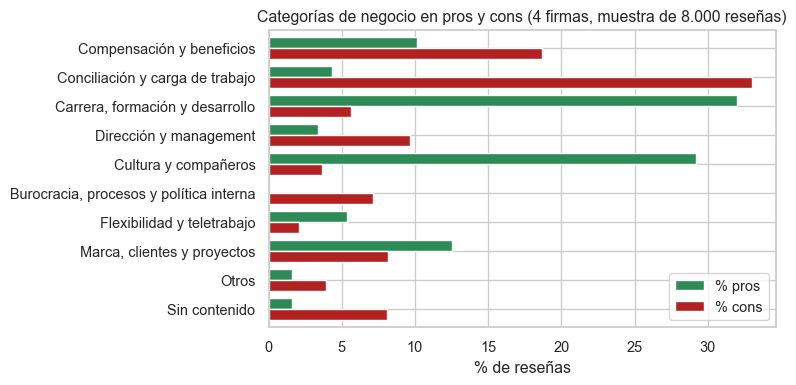

,% pros,% cons
Compensación y beneficios,10.1,18.7
Conciliación y carga de trabajo,4.3,33.0
"Carrera, formación y desarrollo",32.0,5.6
Dirección y management,3.4,9.7
Cultura y compañeros,29.2,3.7
"Burocracia, procesos y política interna",0.0,7.1
Flexibilidad y teletrabajo,5.3,2.1
"Marca, clientes y proyectos",12.5,8.2
Otros,1.6,3.9
Sin contenido,1.6,8.1


In [27]:
# Distribución global de categorías en pros y cons (las 4 firmas juntas)
dist_cat = pd.DataFrame({'% pros': df['cat_pros'].value_counts(normalize=True) * 100,
                         '% cons': df['cat_cons'].value_counts(normalize=True) * 100}).reindex(CATEGORIAS + [SIN_CONTENIDO]).fillna(0)
fig, ax = plt.subplots(figsize=(8, 4))
dist_cat.plot(kind='barh', ax=ax, color=['#2E8B57', '#B22222'], width=0.75)
ax.invert_yaxis(); ax.set_xlabel('% de reseñas'); ax.set_title('Categorías de negocio en pros y cons (4 firmas, muestra de 8.000 reseñas)')
guardar(fig, '07_topics_categorias_global')
dist_cat.round(1)

---
## 4. Comparación con peers

Para cada empresa se calcula el **% de reseñas** cuyos pros caen en cada categoría y lo mismo con los cons; la empresa objetivo se compara con la **media simple de los tres peers**.

> **Cuidado con los porcentajes.** Los porcentajes de cada empresa suman 100 %, así que son relativos: si una empresa tiene pocas quejas de salario, el peso de "salario" en sus cons baja pero sube el del resto aunque nada haya empeorado. Por eso se calcula el **balance neto** por categoría (% en pros − % en cons) y el **gap** del balance frente a la media de peers: un balance por encima del de los peers es una fortaleza relativa; por debajo, una debilidad relativa.

In [28]:
def pct_por_empresa(frame, col):
    """% de reseñas de cada empresa en cada categoría (filas = categorías, columnas = empresas)."""
    ct = pd.crosstab(frame['firm'], frame[col], normalize='index') * 100
    return ct.reindex(index=FIRMS, columns=CATEGORIAS + [SIN_CONTENIDO]).fillna(0).T

pct_pros = pct_por_empresa(df, 'cat_pros'); pct_cons = pct_por_empresa(df, 'cat_cons')
for t in (pct_pros, pct_cons):
    t['Media peers'] = t[PEERS].mean(axis=1)
    t[f'Gap {TARGET}'] = t[TARGET] - t['Media peers']

print(f'PROS: % de reseñas por categoría y empresa'); display(pct_pros.round(1))
print(f'CONS: % de reseñas por categoría y empresa'); display(pct_cons.round(1))

PROS: % de reseñas por categoría y empresa


firm,Deloitte,PwC,EY,KPMG,Media peers,Gap Deloitte
cat_pros,,,,,,
Compensación y beneficios,11.2,9.2,9.6,10.3,9.7,1.5
Conciliación y carga de trabajo,5.1,2.8,4.4,4.9,4.0,1.1
"Carrera, formación y desarrollo",32.8,32.4,30.3,32.4,31.7,1.1
Dirección y management,3.2,3.5,3.3,3.4,3.4,-0.2
Cultura y compañeros,28.4,29.0,28.2,31.0,29.4,-1.0
"Burocracia, procesos y política interna",0.0,0.0,0.0,0.0,0.0,0.0
Flexibilidad y teletrabajo,5.5,6.0,5.8,4.0,5.3,0.2
"Marca, clientes y proyectos",12.2,12.4,14.0,11.6,12.6,-0.5
Otros,0.0,3.0,3.2,0.2,2.2,-2.2


CONS: % de reseñas por categoría y empresa


firm,Deloitte,PwC,EY,KPMG,Media peers,Gap Deloitte
cat_cons,,,,,,
Compensación y beneficios,17.0,17.7,18.6,21.6,19.3,-2.3
Conciliación y carga de trabajo,29.1,37.7,33.5,31.7,34.3,-5.2
"Carrera, formación y desarrollo",6.6,4.6,5.6,5.6,5.3,1.4
Dirección y management,9.9,8.6,10.5,9.6,9.6,0.3
Cultura y compañeros,3.4,3.3,3.6,4.4,3.8,-0.4
"Burocracia, procesos y política interna",7.2,6.6,7.7,7.0,7.1,0.1
Flexibilidad y teletrabajo,2.4,2.0,1.8,2.0,2.0,0.4
"Marca, clientes y proyectos",11.2,7.3,8.0,6.2,7.2,4.1
Otros,3.9,4.4,2.9,4.4,3.9,-0.0


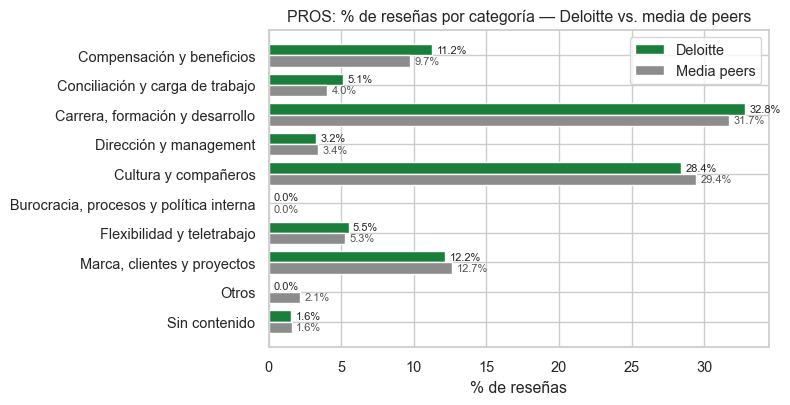

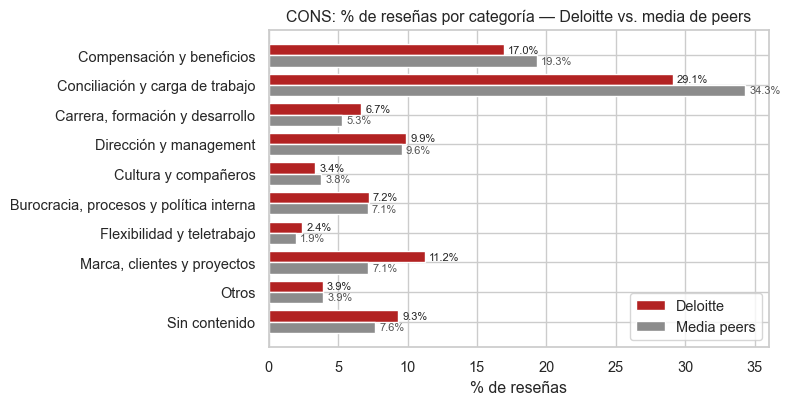

In [29]:
def grafico_target_vs_peers(tabla, titulo, nombre, cats=None, color_target=COLOR_TARGET):
    cats = cats or CATEGORIAS
    t = tabla.loc[cats]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    y = np.arange(len(t)); h = 0.38
    ax.barh(y - h/2, t[TARGET], h, color=color_target, label=TARGET)
    ax.barh(y + h/2, t['Media peers'], h, color=COLOR_MEDIA_PEERS, label='Media peers')
    for i in range(len(t)):
        ax.text(t[TARGET].iloc[i] + 0.3, y[i] - h/2, f'{t[TARGET].iloc[i]:.1f}%', va='center', fontsize=8)
        ax.text(t['Media peers'].iloc[i] + 0.3, y[i] + h/2, f"{t['Media peers'].iloc[i]:.1f}%", va='center', fontsize=8, color='#555')
    ax.set_yticks(y); ax.set_yticklabels(t.index); ax.invert_yaxis(); ax.set_xlabel('% de reseñas'); ax.set_title(titulo); ax.legend()
    guardar(fig, nombre)

grafico_target_vs_peers(pct_pros, f'PROS: % de reseñas por categoría — {TARGET} vs. media de peers', '08_pros_target_vs_peers', cats=CATEGORIAS + [SIN_CONTENIDO])
grafico_target_vs_peers(pct_cons, f'CONS: % de reseñas por categoría — {TARGET} vs. media de peers', '09_cons_target_vs_peers', cats=CATEGORIAS + [SIN_CONTENIDO], color_target='#B22222')

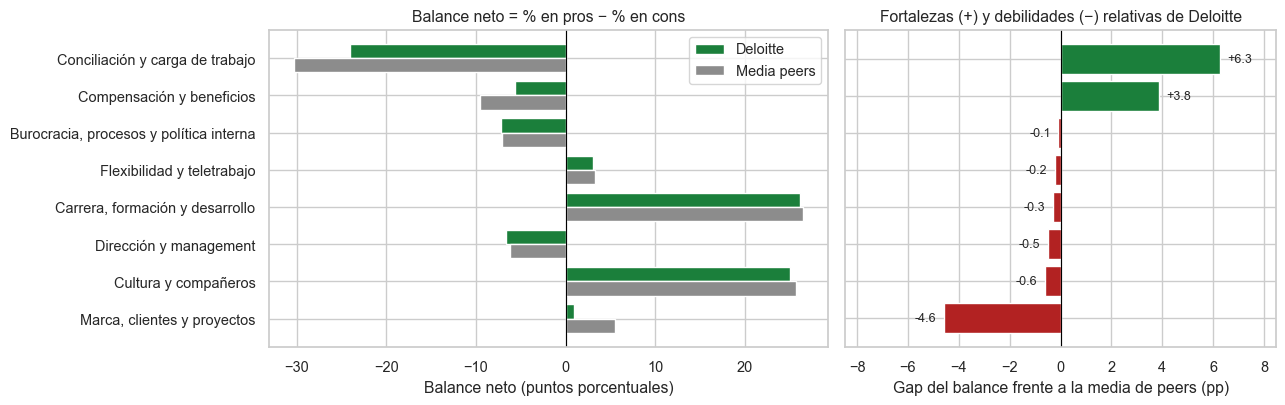

firm,Deloitte,PwC,EY,KPMG,Media peers,Gap Deloitte
cat_pros,,,,,,
Conciliación y carga de trabajo,-24.0,-34.9,-29.1,-26.8,-30.3,6.3
Compensación y beneficios,-5.7,-8.4,-9.0,-11.3,-9.5,3.8
"Burocracia, procesos y política interna",-7.2,-6.6,-7.7,-7.0,-7.1,-0.1
Flexibilidad y teletrabajo,3.1,4.0,3.9,2.0,3.3,-0.2
"Carrera, formación y desarrollo",26.2,27.8,24.6,26.9,26.4,-0.3
Dirección y management,-6.6,-5.1,-7.2,-6.2,-6.2,-0.5
Cultura y compañeros,25.0,25.7,24.6,26.6,25.7,-0.6
"Marca, clientes y proyectos",0.9,5.1,6.0,5.4,5.5,-4.6


In [30]:
# ---------------- Balance neto por categoría (% pros - % cons) y gap frente a peers ----------------
CATS_BALANCE = [c for c in CATEGORIAS if c != 'Otros']
balance = (pct_pros.loc[CATS_BALANCE, FIRMS] - pct_cons.loc[CATS_BALANCE, FIRMS])
balance['Media peers'] = balance[PEERS].mean(axis=1)
balance[f'Gap {TARGET}'] = balance[TARGET] - balance['Media peers']
balance = balance.sort_values(f'Gap {TARGET}', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.3, 1]})
y = np.arange(len(balance)); h = 0.38
axes[0].barh(y - h/2, balance[TARGET], h, color=COLOR_TARGET, label=TARGET)
axes[0].barh(y + h/2, balance['Media peers'], h, color=COLOR_MEDIA_PEERS, label='Media peers')
axes[0].axvline(0, color='black', lw=0.8); axes[0].set_yticks(y); axes[0].set_yticklabels(balance.index); axes[0].invert_yaxis()
axes[0].set_xlabel('Balance neto (puntos porcentuales)'); axes[0].set_title('Balance neto = % en pros − % en cons'); axes[0].legend()
gap = balance[f'Gap {TARGET}']
axes[1].barh(y, gap, color=np.where(gap >= 0, COLOR_TARGET, '#B22222'))
for i, v in enumerate(gap):
    axes[1].text(v + (0.3 if v >= 0 else -0.3), i, f'{v:+.1f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
axes[1].axvline(0, color='black', lw=0.8); axes[1].set_yticks(y); axes[1].set_yticklabels([]); axes[1].invert_yaxis()
axes[1].set_xlabel('Gap del balance frente a la media de peers (pp)'); axes[1].set_title(f'Fortalezas (+) y debilidades (−) relativas de {TARGET}')
lim = max(abs(gap.min()), abs(gap.max())) * 1.35; axes[1].set_xlim(-lim, lim)
guardar(fig, '10_balance_neto_y_gap')
balance.round(1)

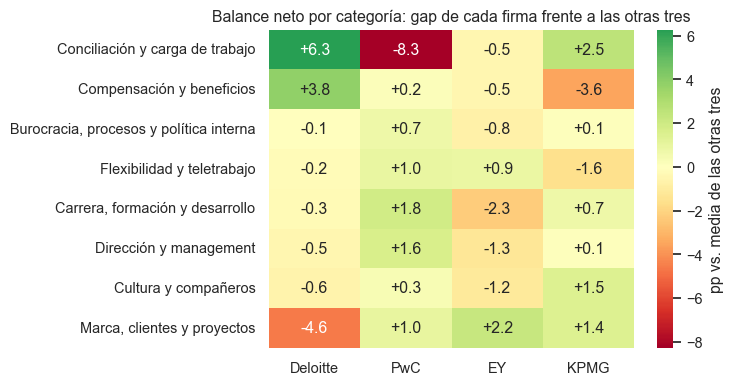

In [31]:
# Mapa de calor: gap de cada empresa frente a la media de las otras tres, en balance neto (visión de conjunto del sector)
gap_todos = pd.DataFrame({f: balance[f] - balance[[o for o in FIRMS if o != f]].mean(axis=1) for f in FIRMS}).loc[balance.index]
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.heatmap(gap_todos, annot=True, fmt='+.1f', cmap='RdYlGn', center=0, cbar_kws={'label': 'pp vs. media de las otras tres'}, ax=ax)
ax.set_title('Balance neto por categoría: gap de cada firma frente a las otras tres'); ax.set_ylabel('')
guardar(fig, '11_heatmap_gap_balance')

### 4.1 Robustez: ¿cambian las conclusiones si no reasignamos los outliers?

In [32]:
# Mismo cálculo del gap en cons usando solo las reseñas que HDBSCAN asignó originalmente (sin outliers reasignados)
df['cat_cons_orig'] = asignar_categoria(df['topic_cons_orig'].where(df['topic_cons_orig'] != -1), df['cons_vacio'], CATEGORIA_CONS)
df['cat_pros_orig'] = asignar_categoria(df['topic_pros_orig'].where(df['topic_pros_orig'] != -1), df['pros_vacio'], CATEGORIA_PROS)
sub = df.dropna(subset=['cat_cons_orig'])
pc_o = pct_por_empresa(sub, 'cat_cons_orig'); pc_o['Media peers'] = pc_o[PEERS].mean(axis=1); pc_o['Gap'] = pc_o[TARGET] - pc_o['Media peers']
rob = pd.DataFrame({'Gap cons (con reasignación)': pct_cons.loc[CATS_BALANCE, f'Gap {TARGET}'],
                    'Gap cons (solo asignadas por HDBSCAN)': pc_o.loc[CATS_BALANCE, 'Gap']}).round(1)
rob['Mismo signo'] = np.sign(rob.iloc[:, 0]) == np.sign(rob.iloc[:, 1])
print(f'Reseñas usadas sin reasignación: {len(sub):,} de {len(df):,}')
rob

Reseñas usadas sin reasignación: 6,050 de 8,000


,Gap cons (con reasignación),Gap cons (solo asignadas por HDBSCAN),Mismo signo
Compensación y beneficios,-2.3,-2.1,True
Conciliación y carga de trabajo,-5.2,-5.3,True
"Carrera, formación y desarrollo",1.4,1.4,True
Dirección y management,0.3,-0.4,False
Cultura y compañeros,-0.4,0.3,False
"Burocracia, procesos y política interna",0.1,-0.8,False
Flexibilidad y teletrabajo,0.4,0.6,True
"Marca, clientes y proyectos",4.1,4.2,True


### 4.2 Contraste con `overall_rating` y `recommend`

Si una categoría es de verdad un problema, las reseñas que se quejan de ella deberían tener **peor rating** y **menor recomendación** que la media de la empresa.

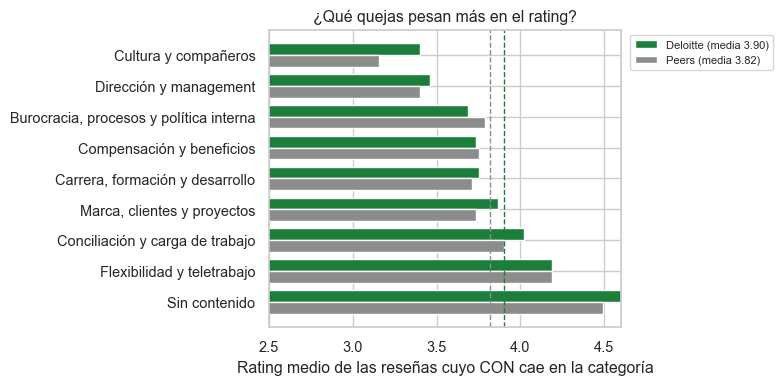

Deloitte: rating medio 3.90 | % recomienda 46.4%


,n,rating_medio,% recomienda,% no recomienda,Δ rating vs media empresa
cat_cons,,,,,
Compensación y beneficios,339,3.73,44.84,13.86,-0.17
Conciliación y carga de trabajo,582,4.02,46.39,7.73,0.12
"Carrera, formación y desarrollo",133,3.75,48.87,14.29,-0.15
Dirección y management,198,3.46,39.39,23.74,-0.44
Cultura y compañeros,67,3.40,35.82,29.85,-0.50
"Burocracia, procesos y política interna",144,3.69,39.58,12.50,-0.22
Flexibilidad y teletrabajo,48,4.19,45.83,6.25,0.28
"Marca, clientes y proyectos",225,3.87,49.33,13.33,-0.04
Sin contenido,186,4.65,58.60,1.61,0.75


In [33]:
def contraste_rating(frame, col='cat_cons', cats=CATS_BALANCE):
    g = frame.groupby(col)
    out = pd.DataFrame({'n': g.size(), 'rating_medio': g['overall_rating'].mean(),
                        '% recomienda': g['recomienda'].apply(lambda s: (s == 'Sí').mean() * 100),
                        '% no recomienda': g['recomienda'].apply(lambda s: (s == 'No').mean() * 100)})
    return out.reindex(cats + [SIN_CONTENIDO]).dropna(subset=['n'])

sub_t = df[df.firm == TARGET]
ct_target = contraste_rating(sub_t); media_t = sub_t.overall_rating.mean()
ct_peers = contraste_rating(df[df.firm.isin(PEERS)]); media_p = df[df.firm.isin(PEERS)].overall_rating.mean()
ct_target['Δ rating vs media empresa'] = ct_target['rating_medio'] - media_t

fig, ax = plt.subplots(figsize=(8, 4))
o = ct_target.sort_values('rating_medio').index
y = np.arange(len(o)); h = 0.38
ax.barh(y - h/2, ct_target.loc[o, 'rating_medio'], h, color=COLOR_TARGET, label=f'{TARGET} (media {media_t:.2f})')
ax.barh(y + h/2, ct_peers['rating_medio'].reindex(o), h, color=COLOR_MEDIA_PEERS, label=f'Peers (media {media_p:.2f})')
ax.axvline(media_t, color=COLOR_TARGET, ls='--', lw=1); ax.axvline(media_p, color=COLOR_MEDIA_PEERS, ls='--', lw=1)
ax.set_yticks(y); ax.set_yticklabels(o); ax.invert_yaxis(); ax.set_xlim(2.5, 4.6); ax.set_xlabel('Rating medio de las reseñas cuyo CON cae en la categoría')
ax.set_title('¿Qué quejas pesan más en el rating?'); ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
guardar(fig, '12_contraste_rating_por_categoria_cons')
print(f'{TARGET}: rating medio {media_t:.2f} | % recomienda {(sub_t.recomienda == "Sí").mean()*100:.1f}%')
ct_target.round(2)

**Lectura de la comparación con peers.** **De qué hablan las Big Four.** Los pros se concentran en dos temas casi "de serie" en el sector: *carrera, formación y desarrollo* (≈32 % de las reseñas en las cuatro firmas) y *cultura y compañeros* (≈29 %). Los cons están dominados por *conciliación y carga de trabajo* (33 % en conjunto) y *compensación* (19 %). El balance neto es, por tanto, muy positivo en carrera y cultura y muy negativo en conciliación **en todas las firmas por igual**: son rasgos estructurales del modelo Big Four, no de Deloitte.

**Dónde difiere Deloitte (gap del balance neto frente a la media de peers):**

- *Conciliación y carga de trabajo* (**+6,3 pp**): sigue siendo la mayor queja en Deloitte (29,1 % de los cons), pero claramente menos que en los peers (34,3 %; PwC 37,7 %), y es además el único tema en el que Deloitte recibe más elogios (5,1 % vs. 4,0 %).
- *Compensación y beneficios* (**+3,8 pp**): menos quejas (17,0 % vs. 19,3 %; KPMG 21,6 %) y más elogios (11,2 % vs. 9,7 %). Junto con lo anterior, Deloitte ofrece la mejor relación esfuerzo-recompensa percibida del grupo.
- *Marca, clientes y proyectos* (**−4,6 pp**): la única debilidad relativa clara. Los elogios a la marca y a la variedad de proyectos son similares (12,2 % vs. 12,6 %), pero las quejas superan ampliamente a las de los peers (11,2 % vs. 7,2 %). Leyendo los topics que la forman (5 y 9 de cons), las quejas hablan de la **asignación y la calidad de los proyectos**: proyectos largos o con tecnología obsoleta, falta de rotación, conciliación que "depende del proyecto", poco contacto con el cliente en los centros de entrega. Es coherente con el mayor peso del negocio de consultoría y tecnología en Deloitte frente a firmas más centradas en auditoría.
- *Carrera* (+1,4 pp en cons), *dirección y management* (+0,3), *burocracia* (+0,1), *cultura* (−0,4) y *flexibilidad* (+0,4): diferencias pequeñas (≤ 1,5 pp); Deloitte está en la media del sector.
- *Sin contenido*: el 9,3 % de las reseñas de Deloitte no encuentran nada que criticar, frente al 7,6 % de los peers.

**Robustez (4.1).** Calculando el gap solo con las reseñas que HDBSCAN asignó por sí mismo (6.050 de 8.000), las cinco categorías con un gap de al menos 1 pp conservan signo y magnitud (conciliación −5,3, proyectos +4,2, compensación −2,1, carrera +1,4); las tres que cambian de signo tienen gaps inferiores a 1 pp y ya se consideraban ruido. La decisión de reasignar los outliers no altera las conclusiones.

**Contraste con el rating y la recomendación (4.2).** Las quejas no pesan igual. Quien se queja de *dirección y management* puntúa **3,46** (−0,44 respecto a la media de 3,90) y el 24 % no recomienda la firma (frente al 13 % general); quien se queja de *cultura* puntúa 3,40 (pocos casos, n = 67) y el 30 % no recomienda. *Burocracia* (3,69), *compensación* (3,73) y *carrera* (3,75) castigan de forma moderada. En cambio, quien se queja de *conciliación* puntúa **4,02, por encima de la media**, y recomienda igual que el resto (46 %): las horas se asumen como "parte del trato" Big Four y no restan satisfacción. Las quejas de *proyectos* tampoco castigan el rating (3,87). **Conclusión de negocio:** la conciliación es el tema más *frecuente*, pero la calidad directiva es el tema más *dañino*.

---
## 5. Empleados actuales vs. antiguos

Los cons de quienes ya se han ido son, en la práctica, **motivos de salida**: el *input* más directo para un plan de retención. Los antiguos empleados puntúan más bajo en todas las empresas (sesgo de selección: quien se va suele estar más descontento), así que la comparación útil es la de **temas**, no la de sentimiento o rating.

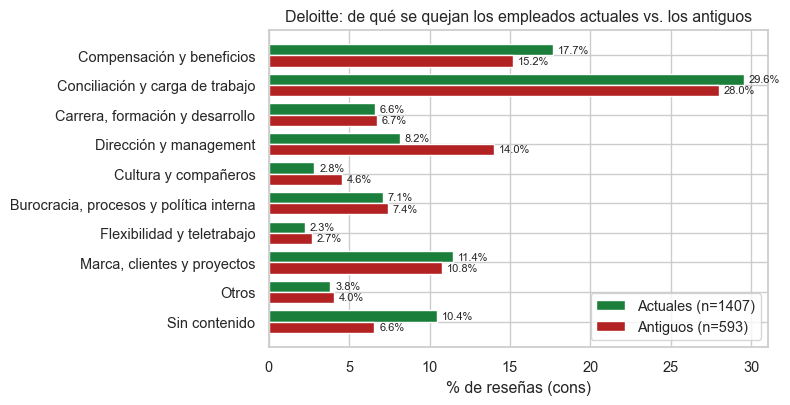

situacion,Actual,Antiguo,Δ (Antiguo − Actual)
cat_cons,,,
Compensación y beneficios,17.7,15.2,-2.5
Conciliación y carga de trabajo,29.6,28.0,-1.6
"Carrera, formación y desarrollo",6.6,6.7,0.1
Dirección y management,8.2,14.0,5.8
Cultura y compañeros,2.8,4.6,1.7
"Burocracia, procesos y política interna",7.1,7.4,0.3
Flexibilidad y teletrabajo,2.3,2.7,0.4
"Marca, clientes y proyectos",11.4,10.8,-0.7
Otros,3.8,4.0,0.2


In [34]:
# 5.1 Cons de empleados actuales vs. antiguos en la empresa objetivo
sit_t = pd.crosstab(sub_t['situacion'], sub_t['cat_cons'], normalize='index').reindex(columns=CATEGORIAS + [SIN_CONTENIDO]).fillna(0).T * 100
sit_t['Δ (Antiguo − Actual)'] = sit_t['Antiguo'] - sit_t['Actual']
n_sit = sub_t['situacion'].value_counts()

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(sit_t)); h = 0.38
ax.barh(y - h/2, sit_t['Actual'], h, color=COLOR_TARGET, label=f'Actuales (n={n_sit.get("Actual", 0)})')
ax.barh(y + h/2, sit_t['Antiguo'], h, color='#B22222', label=f'Antiguos (n={n_sit.get("Antiguo", 0)})')
for i in range(len(sit_t)):
    ax.text(sit_t['Actual'].iloc[i] + 0.3, y[i] - h/2, f"{sit_t['Actual'].iloc[i]:.1f}%", va='center', fontsize=8)
    ax.text(sit_t['Antiguo'].iloc[i] + 0.3, y[i] + h/2, f"{sit_t['Antiguo'].iloc[i]:.1f}%", va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(sit_t.index); ax.invert_yaxis(); ax.set_xlabel('% de reseñas (cons)')
ax.set_title(f'{TARGET}: de qué se quejan los empleados actuales vs. los antiguos'); ax.legend()
guardar(fig, '13_cons_actuales_vs_antiguos_target')
sit_t.round(1)

Reseñas de antiguos empleados por empresa: {'Deloitte': 593, 'PwC': 676, 'EY': 627, 'KPMG': 699}


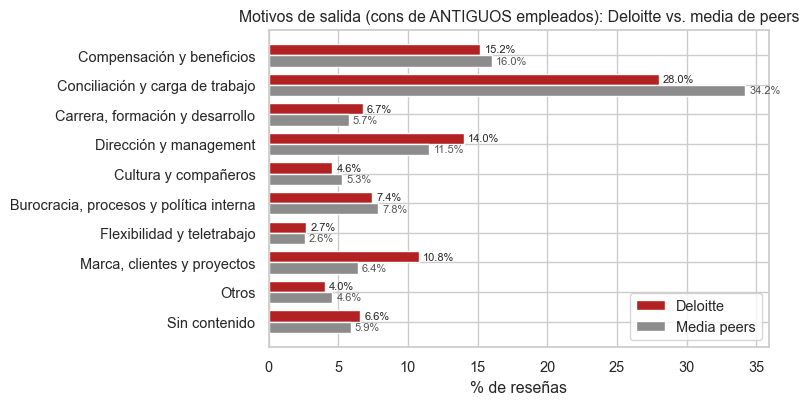

firm,Deloitte,PwC,EY,KPMG,Media peers,Gap Deloitte
cat_cons,,,,,,
Compensación y beneficios,15.2,14.2,15.8,18.0,16.0,-0.8
Conciliación y carga de trabajo,28.0,36.7,34.0,31.9,34.2,-6.2
"Carrera, formación y desarrollo",6.7,5.0,5.9,6.3,5.7,1.0
Dirección y management,14.0,10.9,12.4,11.2,11.5,2.5
Cultura y compañeros,4.6,5.0,5.1,5.7,5.3,-0.7
"Burocracia, procesos y política interna",7.4,8.4,7.5,7.6,7.8,-0.4
Flexibilidad y teletrabajo,2.7,3.1,2.2,2.4,2.6,0.1
"Marca, clientes y proyectos",10.8,6.4,7.7,5.2,6.4,4.4
Otros,4.0,4.7,3.8,5.2,4.6,-0.5


In [35]:
# 5.2 Motivos de salida (cons de antiguos empleados): empresa objetivo vs. peers
ant = df[df.situacion == 'Antiguo']
salida = pct_por_empresa(ant, 'cat_cons'); salida['Media peers'] = salida[PEERS].mean(axis=1); salida[f'Gap {TARGET}'] = salida[TARGET] - salida['Media peers']
print('Reseñas de antiguos empleados por empresa:', ant.firm.value_counts().loc[FIRMS].to_dict())
grafico_target_vs_peers(salida, f'Motivos de salida (cons de ANTIGUOS empleados): {TARGET} vs. media de peers', '14_motivos_salida_vs_peers',
                        cats=CATEGORIAS + [SIN_CONTENIDO], color_target='#B22222')
salida.round(1)

In [36]:
# 5.3 Lo mismo para los pros: qué valoran los que se quedan frente a los que se fueron (empresa objetivo)
sit_p = pd.crosstab(sub_t['situacion'], sub_t['cat_pros'], normalize='index').reindex(columns=CATEGORIAS + [SIN_CONTENIDO]).fillna(0).T * 100
sit_p['Δ (Antiguo − Actual)'] = sit_p['Antiguo'] - sit_p['Actual']
print(f'{TARGET} — PROS por situación (%):'); display(sit_p.round(1))
# Rating por situación en la muestra (confirma el sesgo de selección)
print(df.pivot_table(index='firm', columns='situacion', values='overall_rating', aggfunc='mean').loc[FIRMS].round(2))

Deloitte — PROS por situación (%):


situacion,Actual,Antiguo,Δ (Antiguo − Actual)
cat_pros,,,
Compensación y beneficios,11.3,11.1,-0.2
Conciliación y carga de trabajo,5.3,4.6,-0.8
"Carrera, formación y desarrollo",32.7,33.1,0.4
Dirección y management,3.1,3.5,0.4
Cultura y compañeros,28.0,29.3,1.3
"Burocracia, procesos y política interna",0.0,0.0,0.0
Flexibilidad y teletrabajo,6.8,2.5,-4.2
"Marca, clientes y proyectos",11.4,13.8,2.4
Otros,0.0,0.0,0.0


situacion  Actual  Antiguo
firm                      
Deloitte     3.99     3.71
PwC          3.96     3.74
EY           3.88     3.60
KPMG         3.87     3.61


**Lectura (actuales vs. antiguos).** Los cons de los antiguos empleados de Deloitte se parecen a los de los actuales en casi todo, con una excepción muy clara: **dirección y management pasa del 8,2 % al 14,0 %** (+5,8 pp) y *cultura* del 2,8 % al 4,6 %. Quien se va de Deloitte se queja de sus jefes mucho más que quien se queda; en cambio, compensación (17,7 % → 15,2 %) y conciliación (29,6 % → 28,0 %) pesan algo menos entre los que se fueron. Comparados con los antiguos empleados de los peers, los de Deloitte citan **menos la conciliación** (28,0 % vs. 34,2 %), **más los proyectos** (10,8 % vs. 6,4 %) y **más la dirección** (14,0 % vs. 11,5 %). En los pros, quienes se fueron valoran sobre todo la marca y los proyectos ("bueno para el CV": 13,8 % vs. 11,4 %) y mucho menos la flexibilidad (2,5 % vs. 6,8 % entre los actuales), lo que sugiere que las políticas actuales de flexibilidad son un factor de retención del que la plantilla anterior no disfrutó. El sesgo de selección se confirma en la muestra (actuales 3,99 vs. antiguos 3,71 en Deloitte, y lo mismo en los peers).

**Lectura para RRHH:** los motivos de salida específicos de Deloitte no son ni el salario ni las horas (ahí está mejor que el mercado), sino la **relación con managers y partners** y la **calidad y asignación de los proyectos**. Son, además, palancas sobre las que RRHH puede actuar sin cambiar el modelo de negocio.

---
## 6. Áreas de mejora, matriz de priorización y recomendaciones

**Matriz de priorización.** Eje X: peso de cada categoría en los cons de la empresa objetivo (cuánto se habla de ello). Eje Y: desventaja frente a los peers (gap en % de cons; positivo = se queja más gente que en los peers). El tamaño del punto refleja cuánto castiga esa queja al rating (diferencia entre el rating medio de las reseñas con esa queja y el rating medio de la empresa). Prioridad: arriba a la derecha (mucho peso **y** peor que el mercado).

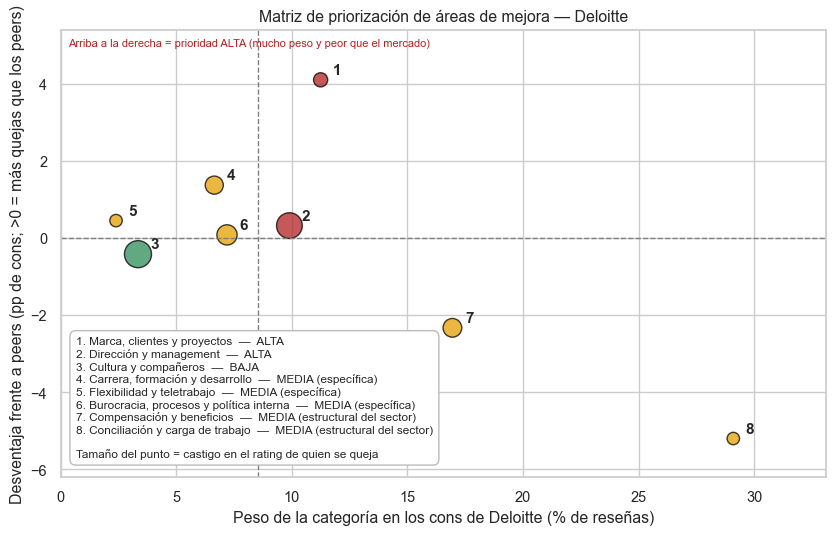

,peso_cons_target,desventaja_vs_peers,gap_balance,castigo_rating,prioridad
"Marca, clientes y proyectos",11.25,4.10,-4.60,0.04,ALTA
Dirección y management,9.90,0.32,-0.48,0.44,ALTA
Cultura y compañeros,3.35,-0.42,-0.62,0.50,BAJA
"Carrera, formación y desarrollo",6.65,1.37,-0.28,0.15,MEDIA (específica)
Flexibilidad y teletrabajo,2.40,0.45,-0.22,-0.28,MEDIA (específica)
"Burocracia, procesos y política interna",7.20,0.08,-0.08,0.22,MEDIA (específica)
Compensación y beneficios,16.95,-2.33,3.85,0.17,MEDIA (estructural del sector)
Conciliación y carga de trabajo,29.10,-5.20,6.27,-0.12,MEDIA (estructural del sector)


In [37]:
prio = pd.DataFrame({'peso_cons_target': pct_cons[TARGET].reindex(CATS_BALANCE),
                     'desventaja_vs_peers': pct_cons[f'Gap {TARGET}'].reindex(CATS_BALANCE),
                     'gap_balance': balance[f'Gap {TARGET}'].reindex(CATS_BALANCE),
                     'castigo_rating': -ct_target['Δ rating vs media empresa'].reindex(CATS_BALANCE)}).round(2)
prio['prioridad'] = np.where((prio.desventaja_vs_peers > 0) & (prio.peso_cons_target >= prio.peso_cons_target.median()), 'ALTA',
                     np.where(prio.desventaja_vs_peers > 0, 'MEDIA (específica)', np.where(prio.peso_cons_target >= prio.peso_cons_target.median(), 'MEDIA (estructural del sector)', 'BAJA')))
prio = prio.sort_values(['prioridad', 'desventaja_vs_peers'], ascending=[True, False])

fig, ax = plt.subplots(figsize=(8.5, 5.5))
xm = prio.peso_cons_target.median()
ax.axvline(xm, color='grey', ls='--', lw=1); ax.axhline(0, color='grey', ls='--', lw=1)
tam = 80 + 600 * np.clip(prio.castigo_rating, 0, None)
col = np.where(prio.prioridad == 'ALTA', '#B22222', np.where(prio.prioridad.str.startswith('MEDIA'), '#E69F00', '#2E8B57'))
ax.scatter(prio.peso_cons_target, prio.desventaja_vs_peers, s=tam, c=col, alpha=0.75, edgecolor='black')
# Etiquetas: cada punto lleva un número y la leyenda (abajo a la izquierda, zona vacía) da el nombre y la prioridad; así nunca se solapan
ax.set_xlim(0, prio.peso_cons_target.max() + 4); ax.set_ylim(prio.desventaja_vs_peers.min() - 1.0, prio.desventaja_vs_peers.max() + 1.3)
for k, (c, r) in enumerate(prio.iterrows(), start=1):
    ax.annotate(str(k), (r.peso_cons_target, r.desventaja_vs_peers), xytext=(9, 4), textcoords='offset points', fontsize=11, fontweight='bold')
leyenda = '\n'.join(f'{k}. {c}  —  {pr}' for k, (c, pr) in enumerate(zip(prio.index, prio.prioridad), start=1))
ax.text(0.02, 0.04, leyenda + '\n\nTamaño del punto = castigo en el rating de quien se queja', transform=ax.transAxes, ha='left', va='bottom',
        fontsize=8.5, bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='#BBBBBB'))
ax.set_xlabel(f'Peso de la categoría en los cons de {TARGET} (% de reseñas)')
ax.set_ylabel('Desventaja frente a peers (pp de cons; >0 = más quejas que los peers)')
ax.set_title(f'Matriz de priorización de áreas de mejora — {TARGET}')
ax.text(0.01, 0.98, 'Arriba a la derecha = prioridad ALTA (mucho peso y peor que el mercado)', transform=ax.transAxes, ha='left', va='top', fontsize=8, color='#B22222')
guardar(fig, '15_matriz_priorizacion')
prio

### 6.1 Fortalezas y áreas de mejora 
**Fortalezas (para employer branding y selección)**

1. **La Big Four mejor valorada y con mejor tendencia:** rating 3,90 (4,00 en 2022) frente a 3,80 de los peers, la mayor recomendación entre quienes opinan (≈79 %) y el menor porcentaje de reseñas de 1-2 estrellas (8,9 %).
2. **La mejor relación esfuerzo-recompensa del grupo:** 5 pp menos de quejas por horas y carga de trabajo (29 % vs. 34 %) y 2 pp menos por salario (17 % vs. 19 %), con más elogios al salario y a la conciliación que cualquier peer.
3. **Los activos del sector, al nivel del mejor:** aprendizaje y carrera (33 % de los pros) y cultura y compañeros (28 %); el 9 % de las reseñas no encuentran nada que criticar (8 % en los peers).

**Áreas de mejora (de la matriz de priorización)**

- **Prioridad alta — Dirección y management.** 9,9 % de los cons (en la media del sector), pero es la queja que más castiga el rating (3,46; 24 % no recomienda), la que más crece entre quienes se van (14 % de sus cons, +2,5 pp sobre los antiguos empleados de los peers) y la que más distingue a quien no recomienda Deloitte (19,7 % de sus cons frente a 8,4 % entre quienes sí recomiendan).
- **Prioridad alta — Asignación y calidad de los proyectos.** La única categoría donde Deloitte está claramente peor que el mercado (11,2 % de los cons vs. 7,2 %) y que va a más (9,6 % en 2018-19 → 14,1 % en 2022-23). No hunde el rating (3,87), pero pesa entre quienes se van (10,8 % vs. 6,4 % en los peers).
- **Prioridad media, específica — Carrera y promoción.** 6,6 % de los cons, 1,4 pp por encima de los peers (promociones lentas, falta de carrera técnica), castigo moderado del rating (3,75).
- **Estructural del sector — Conciliación y compensación.** Las mayores quejas en volumen (29 % y 17 %), pero por debajo de los peers y sin castigo en el rating. No son prioridad de inversión sino de **vigilancia**: las quejas por horas crecen en Deloitte del 26 % (2018-19) al 32 % (2022-23).

### 6.2 Recomendaciones para RRHH (máximo 3) 
1. **Programa de calidad directiva para managers y senior managers.** *Objetivo:* reducir las quejas sobre dirección entre quienes se van del 14 % al nivel de los peers (≈11 %) en 18 meses. *Acciones:* evaluación ascendente (del equipo al manager) con peso real en la promoción a senior manager y partner; formación obligatoria en gestión de personas y en planificación de la carga de trabajo del equipo; identificación trimestral de los equipos con peor feedback ascendente y plan de acompañamiento. *Por qué:* es la queja que más daña el rating y la recomendación y el principal motivo de salida que distingue a Deloitte.
2. **Transparencia y rotación en la asignación de proyectos (staffing).** *Objetivo:* bajar las quejas sobre proyectos del 11 % al 7 % (media de los peers). *Acciones:* un "mercado interno" de proyectos visible para toda la plantilla, con criterios públicos de asignación; revisión obligatoria de la asignación tras 12 meses en el mismo proyecto; plan de modernización tecnológica de los proyectos antiguos y exposición periódica al cliente para los equipos de los centros de entrega. *Por qué:* es la única área donde Deloitte está claramente peor que el mercado y la tendencia empeora.
3. **Convertir la ventaja en esfuerzo-recompensa en mensaje de marca empleadora, y protegerla.** *Acciones:* en campus y en las ofertas, apoyar el mensaje "la Big Four mejor valorada" con hechos verificables (rating 4,0 en 2022, menos quejas por horas y por salario que cualquier competidor, mayor recomendación entre quienes opinan); internamente, fijar reglas de temporada alta (límites de horas y compensación en tiempo libre) y seguir trimestralmente el peso de las quejas por horas, que ha subido 6 pp desde 2018. *Por qué:* es la fortaleza diferencial de Deloitte y la que más fácilmente se pierde si las horas siguen creciendo.

### 6.3 Limitaciones del análisis

- **Representatividad de Glassdoor.** Las reseñas son voluntarias y autoseleccionadas: escriben más quienes tienen una opinión fuerte (muy satisfechos o muy descontentos), y los antiguos empleados puntúan sistemáticamente más bajo. Los niveles absolutos (rating, % que recomienda) deben leerse con cautela; la comparación relativa entre firmas, que comparten el mismo sesgo, es más fiable.
- **Mezcla de países y áreas.** El dataset combina reseñas de todo el mundo (Reino Unido, EE. UU., India...) y de todas las líneas de servicio (auditoría, consultoría, tecnología, soporte). Un problema de "salario" puede concentrarse en un país o en una línea concreta y el análisis agregado lo diluye; con el campo de ubicación o de puesto se podría segmentar.
- **Precisión de los topics.** BERTopic agrupa por similitud semántica; algunos topics mezclan temas y la agrupación en categorías es un juicio manual (un revisor distinto podría agrupar de otra forma). Cada reseña se asigna a **un solo** topic aunque mencione varios temas ("long hours and low pay"), y los outliers reasignados son, por construcción, las reseñas que peor encajan. Los porcentajes deben leerse como órdenes de magnitud (diferencias de 1-2 pp no son significativas).
- **Modelo de sentimiento.** SST-2 está entrenado en críticas de cine; en textos de empleo sin contexto ("nothing", "flexible deadlines") comete errores, como se vio en la sección 2. Aquí solo se usa como control de calidad.
- **Muestra y ventana temporal.** Se modelan 2.000 reseñas por empresa (de 25.000-40.000 disponibles) y la ventana 2018-2023 mezcla el periodo pre-COVID, la pandemia y el retorno a la oficina; los extras de la sección 7 muestran que el peso de algunas categorías cambia en el tiempo.

---
## 7. Extra: evolución temporal de las categorías y análisis por recomendación / antigüedad

Deloitte — reseñas por periodo: {'2018-19': 353, '2020-21': 1171, '2022-23': 476}


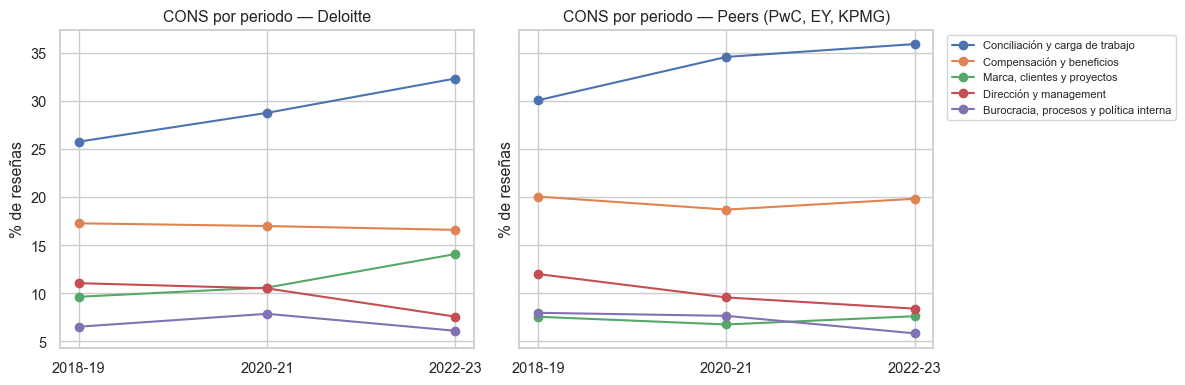

periodo,2018-19,2020-21,2022-23
cat_cons,,,
Compensación y beneficios,17.3,17.0,16.6
Conciliación y carga de trabajo,25.8,28.8,32.4
"Carrera, formación y desarrollo",8.8,6.6,5.3
Dirección y management,11.0,10.5,7.6
Cultura y compañeros,3.1,3.8,2.5
"Burocracia, procesos y política interna",6.5,7.9,6.1
Flexibilidad y teletrabajo,3.1,2.5,1.7
"Marca, clientes y proyectos",9.6,10.6,14.1
Otros,3.7,3.6,4.8


In [38]:
# 7.1 Evolución temporal: peso de las categorías en los cons de la empresa objetivo y de los peers, por periodo
def pct_por_periodo(frame, col):
    return (pd.crosstab(frame['periodo'], frame[col], normalize='index').reindex(columns=CATEGORIAS + [SIN_CONTENIDO]).fillna(0) * 100)

per_t = pct_por_periodo(sub_t, 'cat_cons'); per_p = pct_por_periodo(df[df.firm.isin(PEERS)], 'cat_cons')
print(f'{TARGET} — reseñas por periodo:', sub_t.periodo.value_counts().sort_index().to_dict())
top_cats = pct_cons.loc[CATS_BALANCE, TARGET].sort_values(ascending=False).index[:5]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tabla, titulo in [(axes[0], per_t, f'{TARGET}'), (axes[1], per_p, 'Peers (PwC, EY, KPMG)')]:
    for c in top_cats:
        ax.plot(tabla.index.astype(str), tabla[c], marker='o', label=c)
    ax.set_title(f'CONS por periodo — {titulo}'); ax.set_ylabel('% de reseñas')
axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
guardar(fig, '16_extra_evolucion_categorias_cons')
display(per_t.round(1).T)

In [39]:
# 7.2 Pros por periodo en la empresa objetivo (¿qué fortalezas se refuerzan o se pierden?)
per_tp = pct_por_periodo(sub_t, 'cat_pros')
display(per_tp.round(1).T)

periodo,2018-19,2020-21,2022-23
cat_pros,,,
Compensación y beneficios,9.9,10.8,13.4
Conciliación y carga de trabajo,7.1,4.3,5.7
"Carrera, formación y desarrollo",28.6,34.9,30.7
Dirección y management,2.8,3.8,2.1
Cultura y compañeros,28.0,28.8,27.7
"Burocracia, procesos y política interna",0.0,0.0,0.0
Flexibilidad y teletrabajo,9.1,4.4,5.5
"Marca, clientes y proyectos",14.2,11.1,13.2
Otros,0.0,0.0,0.0


Deloitte — reseñas por recomendación: {'Sí': 928, 'Sin opinión': 834, 'No': 238}


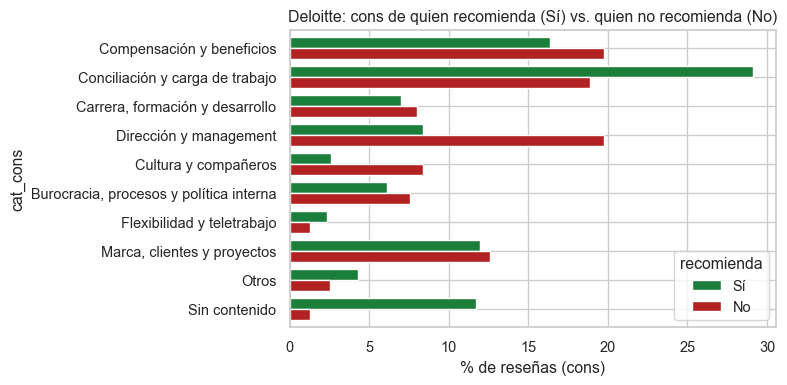

recomienda,Sí,Sin opinión,No,Δ (No − Sí)
cat_cons,,,,
Compensación y beneficios,16.4,16.8,19.7,3.4
Conciliación y carga de trabajo,29.1,32.0,18.9,-10.2
"Carrera, formación y desarrollo",7.0,5.9,8.0,1.0
Dirección y management,8.4,8.8,19.7,11.3
Cultura y compañeros,2.6,2.8,8.4,5.8
"Burocracia, procesos y política interna",6.1,8.3,7.6,1.4
Flexibilidad y teletrabajo,2.4,2.8,1.3,-1.1
"Marca, clientes y proyectos",12.0,10.1,12.6,0.6
Otros,4.3,3.8,2.5,-1.8


In [40]:
# 7.3 Cons según si el empleado recomienda o no la empresa (empresa objetivo)
rec_t = pd.crosstab(sub_t['recomienda'], sub_t['cat_cons'], normalize='index').reindex(index=['Sí', 'Sin opinión', 'No'], columns=CATEGORIAS + [SIN_CONTENIDO]).fillna(0).T * 100
rec_t['Δ (No − Sí)'] = rec_t['No'] - rec_t['Sí']
print(f'{TARGET} — reseñas por recomendación:', sub_t.recomienda.value_counts().to_dict())
fig, ax = plt.subplots(figsize=(8, 4))
rec_t[['Sí', 'No']].plot(kind='barh', ax=ax, color=[COLOR_TARGET, '#B22222'], width=0.75)
ax.invert_yaxis(); ax.set_xlabel('% de reseñas (cons)'); ax.set_title(f'{TARGET}: cons de quien recomienda (Sí) vs. quien no recomienda (No)')
guardar(fig, '17_extra_cons_por_recomendacion')
rec_t.round(1)

Reseñas por tramo de antigüedad: {'n/d': 756, '1-3 años': 466, '3-5 años': 346, '< 1 año': 220, '5-8 años': 150, '8-10 años': 41, '> 10 años': 21}


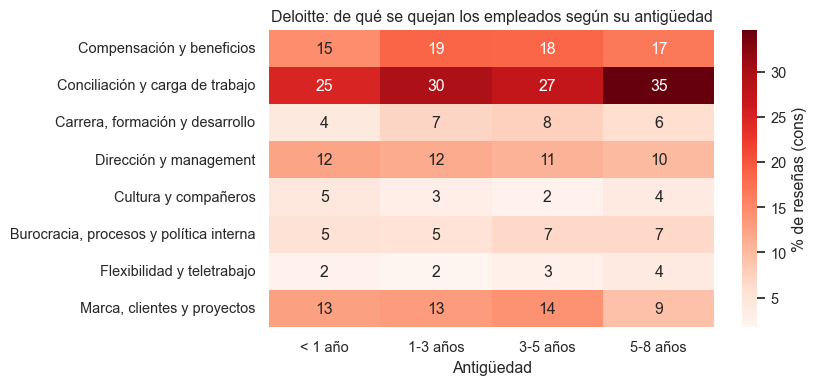

cat_cons,Compensación y beneficios,Conciliación y carga de trabajo,"Carrera, formación y desarrollo",Dirección y management,Cultura y compañeros,"Burocracia, procesos y política interna",Flexibilidad y teletrabajo,"Marca, clientes y proyectos"
antiguedad,,,,,,,,
< 1 año,14.5,25.0,4.1,12.3,4.5,5.5,2.3,12.7
1-3 años,18.7,29.6,7.1,11.6,3.0,5.4,1.7,13.1
3-5 años,18.5,27.5,7.5,11.0,2.3,6.6,2.6,14.2
5-8 años,16.7,34.7,6.0,10.0,4.0,6.7,4.0,9.3


In [41]:
# 7.4 Cons por antigüedad (empresa objetivo; solo tramos con >= 100 reseñas)
n_ant = sub_t['antiguedad'].value_counts()
tramos = [t for t in ORDEN_ANTIG if n_ant.get(t, 0) >= 100 and t != 'n/d']
ant_t = pd.crosstab(sub_t['antiguedad'], sub_t['cat_cons'], normalize='index').reindex(index=tramos, columns=CATEGORIAS + [SIN_CONTENIDO]).fillna(0) * 100
print('Reseñas por tramo de antigüedad:', n_ant.to_dict())
fig, ax = plt.subplots(figsize=(8.5, 4))
sns.heatmap(ant_t[CATS_BALANCE].T, annot=True, fmt='.0f', cmap='Reds', ax=ax, cbar_kws={'label': '% de reseñas (cons)'})
ax.set_title(f'{TARGET}: de qué se quejan los empleados según su antigüedad'); ax.set_xlabel('Antigüedad'); ax.set_ylabel('')
guardar(fig, '18_extra_cons_por_antiguedad')
ant_t[CATS_BALANCE].round(1)

**Lectura de los extras.** - **Evolución temporal.** En Deloitte, las quejas por *conciliación* suben de forma sostenida (25,8 % → 28,8 % → 32,4 %) y las de *proyectos* también (9,6 % → 10,6 % → 14,1 %), mientras bajan las de *dirección* (11,0 % → 7,6 %) y *carrera* (8,8 % → 5,3 %). En los peers la conciliación también crece, así que el aumento de horas es sectorial (vuelta a la oficina y presión de 2022), pero el problema de proyectos es propio de Deloitte. En los pros, los elogios a la *compensación* suben del 9,9 % al 13,4 % (coincide con las subidas salariales de 2022) y los de *flexibilidad* bajan (9,1 % → 5,5 %): la flexibilidad dejó de ser un diferencial cuando se generalizó tras la pandemia.
- **Por recomendación.** Las reseñas que **no** recomiendan Deloitte (12 % de la muestra) se quejan de *dirección* (19,7 % vs. 8,4 % entre quienes recomiendan), *cultura* (8,4 % vs. 2,6 %) y *compensación* (19,7 % vs. 16,4 %); en cambio, mencionan **menos** la *conciliación* (18,9 % vs. 29,1 %). Confirma la sección 4: las horas no hacen que alguien deje de recomendar la firma; los jefes y la cultura, sí.
- **Por antigüedad.** Las quejas por *conciliación* crecen con la antigüedad (25 % con menos de un año, 35 % con 5-8 años) y las de *compensación* alcanzan su máximo entre 1 y 5 años (18-19 %), el momento de la primera promoción. *Dirección* (10-12 %) y *proyectos* (9-14 %) son estables en todos los tramos: no es un problema de "recién llegados".

---
## 8. Conclusiones 

**Hallazgos de negocio más relevantes (Deloitte vs. PwC, EY y KPMG, Glassdoor 2018-2023)**

1. **Deloitte es la Big Four mejor valorada por sus empleados y mejora:** rating 3,90 (4,00 en 2022) frente a 3,80 de los peers; la mayor recomendación entre quienes opinan (≈79 % vs. 74-78 %); el menor porcentaje de reseñas de 1-2 estrellas. La caída del "% que recomienda" bruto es un artefacto (crece el "sin opinión") y no debe comunicarse como deterioro.
2. **El dato textual es fiable:** 95 % de los pros son positivos y 82 % de los cons negativos según DistilBERT; los discordantes son reseñas sin queja, listas de temas sin polaridad y elogios con jerga, no errores del pipeline.
3. **Las Big Four comparten el mismo contrato:** se elogia la carrera y el aprendizaje (32 % de los pros) y la cultura (29 %); se critica la carga de trabajo (33 % de los cons) y el salario (19 %). Son rasgos del sector, no de Deloitte.
4. **Fortalezas diferenciales de Deloitte:** menos quejas por horas (29 % vs. 34 %) y por salario (17 % vs. 19 %) y más elogios en ambos temas: la mejor relación esfuerzo-recompensa del grupo. Más reseñas sin ninguna queja (9 % vs. 8 %).
5. **Debilidad diferencial:** la asignación y calidad de los proyectos (11 % de los cons vs. 7 % en los peers, y en aumento: 14 % en 2022-23).
6. **Lo que de verdad daña y provoca salidas es la calidad directiva:** quien se queja de sus managers puntúa 3,46 y el 24 % no recomienda; el tema pasa del 8 % de los cons entre los actuales al 14 % entre los antiguos empleados (11,5 % en los peers) y al 20 % entre quienes no recomiendan. Las horas, en cambio, se asumen (rating 4,02) y no restan recomendación.
7. **Tres recomendaciones:** (1) programa de calidad directiva con evaluación ascendente ligada a la promoción; (2) transparencia y rotación en el staffing de proyectos; (3) usar la ventaja en esfuerzo-recompensa como mensaje de marca empleadora y protegerla con reglas de temporada alta.

**Próximos pasos propuestos**

- Segmentar por país y línea de servicio (el dataset original de Kaggle incluye ubicación y puesto) para localizar dónde se concentran las quejas de proyectos y de dirección.
- Clasificación multietiqueta por aspectos: una reseña que menciona horas y salario debería contar en ambas categorías; entrenar un clasificador con las 8.000 etiquetas actuales y aplicarlo a las 129.000 reseñas.
- Seguimiento trimestral automatizado (mismo pipeline) con alertas cuando el peso de una categoría cambie más de 3 pp, y cruce con encuestas internas de clima y entrevistas de salida.

In [42]:
# Resumen numérico final (se imprime desde los datos para que las conclusiones sean verificables)
print(f'Empresa: {TARGET} | Peers: {", ".join(PEERS)} | Muestra NLP: {len(df):,} reseñas | EDA: {len(raw):,} reseñas')
print(f'\nRating medio: {resumen.loc[TARGET, "rating_medio"]:.2f} vs media peers {resumen.loc["Media peers", "rating_medio"]:.2f}')
print(f'% recomienda: {resumen.loc[TARGET, "% recomienda (Sí)"]:.1f}% vs media peers {resumen.loc["Media peers", "% recomienda (Sí)"]:.1f}%')
print(f'\nControl de calidad sentimiento: {qc.loc["TOTAL", "% pros POSITIVE"]:.1f}% pros positivos, {qc.loc["TOTAL", "% cons NEGATIVE"]:.1f}% cons negativos')
print(f'\nFortalezas relativas (gap balance neto > 0):')
print(balance[balance[f"Gap {TARGET}"] > 0][[TARGET, "Media peers", f"Gap {TARGET}"]].round(1).to_string())
print(f'\nDebilidades relativas (gap balance neto < 0):')
print(balance[balance[f"Gap {TARGET}"] < 0][[TARGET, "Media peers", f"Gap {TARGET}"]].round(1).to_string())
print('\nMatriz de priorización:'); print(prio[['peso_cons_target', 'desventaja_vs_peers', 'castigo_rating', 'prioridad']].to_string())

Empresa: Deloitte | Peers: PwC, EY, KPMG | Muestra NLP: 8,000 reseñas | EDA: 129,115 reseñas

Rating medio: 3.90 vs media peers 3.80
% recomienda: 46.2% vs media peers 41.6%

Control de calidad sentimiento: 94.7% pros positivos, 82.4% cons negativos

Fortalezas relativas (gap balance neto > 0):
firm                             Deloitte  Media peers  Gap Deloitte
cat_pros                                                            
Conciliación y carga de trabajo     -24.0        -30.3           6.3
Compensación y beneficios            -5.7         -9.5           3.8

Debilidades relativas (gap balance neto < 0):
firm                                     Deloitte  Media peers  Gap Deloitte
cat_pros                                                                    
Burocracia, procesos y política interna      -7.2         -7.1          -0.1
Flexibilidad y teletrabajo                    3.1          3.3          -0.2
Carrera, formación y desarrollo              26.2         26.4          -

---
### Referencias

- Gauthier, D. *Glassdoor Job Reviews* [dataset]. Kaggle. https://www.kaggle.com/datasets/davidgauthier/glassdoor-job-reviews
- Gauthier, D. *Glassdoor Job Reviews 2* [dataset]. Kaggle. https://www.kaggle.com/datasets/davidgauthier/glassdoor-job-reviews-2
- Grootendorst, M. (2022). *BERTopic: Neural topic modeling with a class-based TF-IDF procedure.* arXiv:2203.05794.
- Sanh, V., Debut, L., Chaumond, J. & Wolf, T. (2019). *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter.* arXiv:1910.01108.
- Reimers, N. & Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks.* EMNLP. (modelo `all-MiniLM-L6-v2`)
- McInnes, L., Healy, J. & Melville, J. (2018). *UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction.* arXiv:1802.03426.
- Campello, R., Moulavi, D. & Sander, J. (2013). *Density-Based Clustering Based on Hierarchical Density Estimates.* PAKDD. (HDBSCAN)
- Socher, R. et al. (2013). *Recursive Deep Models for Semantic Compositionality Over a Sentiment Treebank.* EMNLP. (SST-2)